# MARV Gene 4 Small ORF Inhibitor Prediction — Final Pipeline

17 parts. Every part produces something that goes directly into the paper (a table, a figure, or both) — nothing exploratory. Run top to bottom in one Kaggle session (Python 3.10+).

**Pipeline (1–6):** load/canonicalize/dedupe → hybrid feature generation → leakage-free split-then-select → ENN cleaning + scaling + export → 10 base classifiers (GridSearchCV) → 8 ensembles (every LGBM/XGB/ET pair + the triple, Soft Voting and Stacking). Champion = highest PR-AUC on the held-out test set, chosen once in Part 6 and read everywhere downstream via `winning_model_name` — no cell hardcodes a model name. A paired bootstrap test in Part 6 checks whether the champion's PR-AUC edge over the best single base model is statistically real; a head-to-head bar chart in Part 7 shows the trade-off honestly, including the metric (Accuracy) where the single model currently wins.

**Explainability (8–9):** SHAP beeswarm for the champion (Part 8) — exact per-member `TreeExplainer` averaging for a Soft-Voting champion (SHAP is linear under averaging, so this is exact, not approximate), with a `KernelExplainer` fallback for anything else. A separate cross-architecture consensus plot (Part 9) compares the champion's and best base model's *native* `feature_importances_` — a second, independent interpretability method, kept as its own figure rather than merged with SHAP since it answers a different question (do two independently-built rankings agree, vs. what drives this specific model).

**Evaluation (10–12):** LIME case study, confusion matrices (champion vs. best single model), and a combined ROC+PR 2×2 figure computed from real per-compound probabilities — no synthetic curve-shaping anywhere in this notebook.

**Chemical-space and screening diagnostics (13–16):** t-SNE overlay, screening-enrichment + scaffold-hopping (one figure), scaffold diversity (frequency bar chart using the actual scaffold SMILES as labels, plus the real 2D drawn structures via RDKit), and QED/SAS drug-likeness paired with the Lipinski/Veber/PAINS ADMET table — computed from one shared RDKit pass rather than two independent (and previously inconsistent) ones.

**Summary (17):** base-classifier and ensemble metrics as two full-width bar charts (not squeezed into subplot panels — with 8-10 rotated model-name labels, that got cramped).

**Bootstrap 95% CIs** are computed for *every* model, base and ensemble alike (Part 5/6, in the master results table) — not just the champion in isolation, so any two models can be honestly compared on more than a point estimate.

**Known-fixed bugs, for the record:** SMILES-to-prediction misalignment (SMILES are now tracked from Part 2 onward and split alongside features, never reconstructed later); feature-selection leakage (split now happens before variance/collinearity filtering and scaling, both fit on train only); fabricated ROC curves in an early draft (replaced with curves computed from real predictions); ADMET pass-rates that used to report the background pool only, never the leads (both sides reported now); a SHAP broadcasting crash caused by different sklearn tree models returning different array shapes from the same call (handled explicitly); silent mock-data fallbacks removed throughout (missing files/variables raise a clear error instead of substituting fake data).

**Parts 18-20 (optional, added on request):** external validation on an independent PubChem assay (AID 720532, Part 18), Tanimoto-based applicability domain (Part 19), and exploratory molecular docking against the Marburg GP1 structural surrogate (PDB 5UQY, Part 20). These three are separable from the core pipeline — if the external dataset isn't uploaded, or docking dependencies aren't available in a given environment, everything through Part 17 already stands as a complete, submittable result on its own. Decide what to include in the paper *after* seeing what these three sections actually produce, not before.

**Part 21 (added on request):** 5-fold cross-validation comparing all 10 base models and all 8 ensembles fold-wise (fixed hyperparameters from Part 5, no re-tuning per fold — the grids were trimmed for exactly this reason) — a robustness layer on top of the single 80/20 split, not a replacement for it. Answers "does the ensemble's advantage hold up across different splits, or was Part 6's result specific to one split?" directly, with fold-wise results and a per-model summary both saved to CSV, plus box-plot comparisons (base vs. ensemble, champion starred) for PR-AUC and Accuracy.

**Bootstrap CIs now cover all 15 numeric metrics** (`capture_metrics()`'s full output — Accuracy, MCC, Kappa, Active/Macro/Weighted Precision-Recall-F1, both ROC-AUC variants, PR-AUC), not just four, for every model in the master table.

In [ ]:
!pip install rdkit catboost lightgbm xgboost imbalanced-learn shap lime seaborn -q

## Part 1 — Load, canonicalize, and deduplicate

Loads the official PubChem AID 540276 active/inactive datatables. SMILES are canonicalized via RDKit *before* dedup/overlap checks (catches the same molecule written two different ways, which raw-string matching would miss), then density-anchored to a computationally tractable ~1:5 ratio before descriptor generation (full-corpus distance/collinearity computation on ~200k compounds isn't RAM-feasible). This ratio is a disclosed design choice, not a way to hide the true ~1:44 raw prevalence.

In [2]:
import pandas as pd
import numpy as np
import warnings
from rdkit import Chem
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')

# =====================================================================
# PART 1: LOAD, CANONICALIZE & DEDUPLICATE
# =====================================================================
print("📂 Loading full Active and Inactive data records...")
active_path = '/kaggle/input/datasets/suyaibalsifat/aid-final/AID_540276_datatable_active.csv'
inactive_path = '/kaggle/input/datasets/suyaibalsifat/aid-final/AID_540276_datatable_inactive.csv'

smiles_col = 'PUBCHEM_EXT_DATASOURCE_SMILES'

df_act = pd.read_csv(active_path, low_memory=False).dropna(subset=[smiles_col])
df_inact = pd.read_csv(inactive_path, low_memory=False).dropna(subset=[smiles_col])

# Canonicalize BEFORE dedup/overlap checks -- catches the same molecule
# written as two different (but chemically identical) SMILES strings,
# which raw-string deduplication would silently miss.
def canonicalize_smiles(smi):
    mol = Chem.MolFromSmiles(str(smi))
    return Chem.MolToSmiles(mol, canonical=True) if mol else None

print("🧬 Canonicalizing SMILES strings...")
df_act['CANONICAL_SMILES'] = df_act[smiles_col].apply(canonicalize_smiles)
df_inact['CANONICAL_SMILES'] = df_inact[smiles_col].apply(canonicalize_smiles)
df_act = df_act.dropna(subset=['CANONICAL_SMILES'])
df_inact = df_inact.dropna(subset=['CANONICAL_SMILES'])

overlap = set(df_act['CANONICAL_SMILES']).intersection(set(df_inact['CANONICAL_SMILES']))
print(f"🧹 Removing {len(overlap)} conflicting structural overlaps...")
df_act = df_act[~df_act['CANONICAL_SMILES'].isin(overlap)].drop_duplicates(subset=['CANONICAL_SMILES'])
df_inact = df_inact[~df_inact['CANONICAL_SMILES'].isin(overlap)].drop_duplicates(subset=['CANONICAL_SMILES'])

df_act['ACTIVITY'] = 1
df_inact['ACTIVITY'] = 0

df_all = pd.concat([
    df_act[['CANONICAL_SMILES', 'ACTIVITY']], df_inact[['CANONICAL_SMILES', 'ACTIVITY']]
], axis=0).reset_index(drop=True)
print(f"📊 Total Deduplicated Base: Active={len(df_act):,} | Inactive={len(df_inact):,}")

print("\n⚡ Downsampling to anchor density bounds before RDKit extraction...")
rus = RandomUnderSampler(sampling_strategy=0.2, random_state=42)
X_res, y_res = rus.fit_resample(df_all[['CANONICAL_SMILES']], df_all['ACTIVITY'])

df_processing_pool = pd.DataFrame({
    'SMILES': X_res['CANONICAL_SMILES'].values,
    'ACTIVITY': y_res.values
})
print(f"🎯 Optimization pool ready for extraction: {df_processing_pool.shape[0]:,} compounds")
print(f"   ↳ Inactive Distribution: {np.sum(df_processing_pool['ACTIVITY'] == 0):,}")
print(f"   ↳ Active Distribution: {np.sum(df_processing_pool['ACTIVITY'] == 1):,}")

📂 Loading full Active and Inactive data records...
🧬 Canonicalizing SMILES strings...


[02:29:24] WARNING: not removing hydrogen atom without neighbors


🧹 Removing 109 conflicting structural overlaps...
📊 Total Deduplicated Base: Active=4,591 | Inactive=201,046

⚡ Downsampling to anchor density bounds before RDKit extraction...
🎯 Optimization pool ready for extraction: 27,546 compounds
   ↳ Inactive Distribution: 22,955
   ↳ Active Distribution: 4,591


## Part 2 — Hybrid molecular feature generation

2048-bit Morgan fingerprints (RDKit) + all available RDKit physicochemical descriptors, computed with explicit column names so SHAP/feature-importance output stays human-readable. SMILES are retained alongside every feature row (`valid_smiles_list`) so predictions can always be traced back to the exact structure that produced them — no reconstruction needed downstream, which is what avoids the SMILES-misalignment problem entirely. NaN/Inf descriptor values are median-imputed rather than zero-filled, since zero is frequently inside the valid range for these descriptors and would distort rather than neutralize them.

In [3]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors

# =====================================================================
# PART 2: HYBRID MOLECULAR FEATURE GENERATION WITH NAMES
# =====================================================================
print("🧪 Initializing RDKit Feature Extraction Engines...")
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
desc_names = [d[0] for d in Descriptors._descList]
physchem_calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)

morgan_names = [f"{i}_Morgan" for i in range(2048)]
all_feature_names = morgan_names + desc_names
print(f"📋 Total Named Features Registered: {len(all_feature_names):,} columns")

def get_features(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return None
    fp = np.array(morgan_gen.GetFingerprintAsNumPy(mol))
    desc = np.array(physchem_calc.CalcDescriptors(mol))
    return np.concatenate([fp, desc])

features_list, valid_y, valid_smiles_list = [], [], []

print(f"🧬 Extracting features from {df_processing_pool.shape[0]:,} compounds...")
for idx, row in df_processing_pool.iterrows():
    feats = get_features(row['SMILES'])
    if feats is not None:
        features_list.append(feats)
        valid_y.append(row['ACTIVITY'])
        valid_smiles_list.append(row['SMILES'])

X_calc = np.array(features_list)
y_calc = np.array(valid_y)
smiles_calc = np.array(valid_smiles_list)

X_df = pd.DataFrame(X_calc, columns=all_feature_names)
# Median imputation rather than zero-fill -- zero is frequently a valid,
# meaningful value for these descriptors (e.g. counts, charges), so filling
# with it would distort rather than neutralize missing/infinite entries.
X_df = X_df.replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median())

print("\n🏁 Part 2 Complete!")
print(f"📊 Raw Named Feature Matrix Shape: {X_df.shape[0]:,} molecules × {X_df.shape[1]:,} columns")

🧪 Initializing RDKit Feature Extraction Engines...
📋 Total Named Features Registered: 2,265 columns
🧬 Extracting features from 27,546 compounds...

🏁 Part 2 Complete!
📊 Raw Named Feature Matrix Shape: 27,546 molecules × 2,265 columns


## Part 3 — Split first, then feature selection (leakage-free)

**Reordered from an earlier version of this pipeline that fit the variance and collinearity filters on the full dataset *before* splitting.** That's a real leakage path: which columns get kept was being decided using information from what should have been the untouched test set. Below, the test set is carved off first (with SMILES split alongside it), and both the variance filter and the collinearity filter are fit strictly on the training partition, then only *applied* (`.transform()`, or the same drop-list) to test.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold

# =====================================================================
# PART 3: SPLIT FIRST, THEN FEATURE SELECTION (NO LEAKAGE)
# =====================================================================
print("🔒 Step 1: Isolating untouched Test Set (20% Stratified Split) FIRST...")
# smiles_calc is split alongside X/y right here -- not derived later by
# replaying train_test_split on a reconstructed array -- so every later
# cell that needs test-set SMILES uses this exact, unambiguous mapping.
X_train_raw, X_test_raw, y_train_raw, y_test, smiles_train_raw, smiles_test = train_test_split(
    X_df, y_calc, smiles_calc, test_size=0.2, stratify=y_calc, random_state=42
)

print("✂️ Step 2: Low-Variance Filter (fit strictly on train)...")
var_selector = VarianceThreshold(threshold=(.997 * (1 - .997)))
X_train_var = var_selector.fit_transform(X_train_raw)
X_test_var = var_selector.transform(X_test_raw)  # transform only -- never refit on test
kept_variance_columns = X_train_raw.columns[var_selector.get_support()]
X_train_var_df = pd.DataFrame(X_train_var, columns=kept_variance_columns)
X_test_var_df = pd.DataFrame(X_test_var, columns=kept_variance_columns)

print("✂️ Step 3: Multi-Collinearity Filter (r > 0.95, computed on train only)...")
corr_matrix = X_train_var_df.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]

X_train_final = X_train_var_df.drop(columns=to_drop)
X_test_final = X_test_var_df.drop(columns=to_drop)
final_feature_names = X_train_final.columns.tolist()

print(f"📉 Columns optimized from {X_df.shape[1]} down to {len(final_feature_names)}")
print("🏁 Part 3 Leakage-Free Feature Selection Complete!")

🔒 Step 1: Isolating untouched Test Set (20% Stratified Split) FIRST...
✂️ Step 2: Low-Variance Filter (fit strictly on train)...
✂️ Step 3: Multi-Collinearity Filter (r > 0.95, computed on train only)...
📉 Columns optimized from 2265 down to 1943
🏁 Part 3 Leakage-Free Feature Selection Complete!


## Part 4 — ENN cleaning, scaling, and export (leakage-free)

ENN cleaning runs on the training partition only (the test set from Part 3 is never resampled). `StandardScaler` is fit strictly on train and only *applied* to test — matching the same fit-on-train/transform-on-test discipline as Part 3's feature selection. Ends with a consolidated data-flow summary (raw counts through to final train/test composition) usable directly as a Methods table.

In [5]:
from imblearn.under_sampling import EditedNearestNeighbours
from sklearn.preprocessing import StandardScaler

# =====================================================================
# PART 4: TOPOLOGICAL CLEANSING, SCALING & EXPORT (NO LEAKAGE)
# =====================================================================
print("⚖️ Step 1: Edited Nearest Neighbours cleaning (training partition only)...")
enn = EditedNearestNeighbours(sampling_strategy='majority', n_neighbors=3)
X_train_enn, y_train = enn.fit_resample(X_train_final, y_train_raw)
print(f"✅ Training set: {len(y_train_raw):,} -> {len(y_train):,} rows after ENN")

neg_count = np.sum(y_train == 0)
pos_count = np.sum(y_train == 1)
scale_pos_weight_value = neg_count / pos_count
print(f"🎯 Imbalance Penalty Scale Factor: {scale_pos_weight_value:.4f}")

print("\n⚖️ Step 2: Z-Score Standardization (fit on train, transform test)...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enn)
X_test_scaled = scaler.transform(X_test_final)  # transform only -- zero leakage into test

print("\n💾 Step 3: Writing named, compressed feature files to disk...")
train_features = pd.DataFrame(X_train_scaled, columns=final_feature_names)
train_features['ACTIVITY'] = y_train.astype(int)

test_features = pd.DataFrame(X_test_scaled, columns=final_feature_names)
test_features['ACTIVITY'] = y_test.astype(int)
test_features['SMILES'] = smiles_test  # carried through for Parts 16-19

train_features.to_csv('FINAL_MARBURG_TRAIN_FEATURES.csv.gz', index=False, compression='gzip')
test_features.to_csv('FINAL_MARBURG_TEST_FEATURES.csv.gz', index=False, compression='gzip')

print("🏁 Part 4 Complete! Data is clean, leakage-free, and journal-ready.")

# --- Data-flow summary table, useful directly as a Methods/Table 1 reference ---
print("\n📋 DATA FLOW SUMMARY (for manuscript Table 1 / Methods):")
summary_rows = [
    ("Raw active / inactive (post structural-overlap purge)", f"{len(df_act):,} / {len(df_inact):,}"),
    ("Density-anchored pool (Part 1, ~1:5)", f"{df_processing_pool.shape[0]:,} total"),
    ("Valid RDKit-parsed compounds (Part 2)", f"{X_df.shape[0]:,}"),
    ("Feature dimensions: raw -> selected", f"{X_df.shape[1]:,} -> {len(final_feature_names):,}"),
    ("Train / test split (80:20, stratified)", f"{len(y_train_raw):,} / {len(y_test):,}"),
    ("Train set after ENN cleaning", f"{len(y_train_raw):,} -> {len(y_train):,}"),
    ("Final test set (Active / Inactive)", f"{int(np.sum(y_test==1)):,} / {int(np.sum(y_test==0)):,}"),
]
for label, value in summary_rows:
    print(f"   {label:<55} {value}")

⚖️ Step 1: Edited Nearest Neighbours cleaning (training partition only)...
✅ Training set: 22,036 -> 14,992 rows after ENN
🎯 Imbalance Penalty Scale Factor: 3.0817

⚖️ Step 2: Z-Score Standardization (fit on train, transform test)...

💾 Step 3: Writing named, compressed feature files to disk...
🏁 Part 4 Complete! Data is clean, leakage-free, and journal-ready.

📋 DATA FLOW SUMMARY (for manuscript Table 1 / Methods):
   Raw active / inactive (post structural-overlap purge)   4,591 / 201,046
   Density-anchored pool (Part 1, ~1:5)                    27,546 total
   Valid RDKit-parsed compounds (Part 2)                   27,546
   Feature dimensions: raw -> selected                     2,265 -> 1,943
   Train / test split (80:20, stratified)                  22,036 / 5,510
   Train set after ENN cleaning                            22,036 -> 14,992
   Final test set (Active / Inactive)                      918 / 4,592


## Part 5 — Ten base classifiers, GridSearchCV-tuned

Every model is optimized for `average_precision` (PR-AUC) under 5-fold stratified CV, matched to the class imbalance with `scale_pos_weight` / `class_weight='balanced'` where the estimator supports it. Each model's real per-compound test-set probabilities are kept in `df_probs` for Part 12's ROC/PR curves — nothing there gets recomputed or approximated later. Every model's row also gets a 95% bootstrap confidence interval (Accuracy/ROC-AUC/PR-AUC/Macro-F1) computed here directly, rather than only for the champion after the fact — so any two models' results can be honestly compared, not just their point estimates.

In [6]:
import joblib
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (classification_report, accuracy_score, matthews_corrcoef,
                              cohen_kappa_score, roc_auc_score, average_precision_score, f1_score)
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

# =====================================================================
# PART 5: TEN-ARCHITECTURE BASE CLASSIFIER TRAINING (GRIDSEARCHCV)
# =====================================================================
models_config = {
    "XGBoost": (
        xgb.XGBClassifier(tree_method='hist', scale_pos_weight=scale_pos_weight_value, eval_metric='aucpr', random_state=42),
        {'n_estimators': [300, 500], 'learning_rate': [0.05], 'max_depth': [6, 8]}
    ),
    "LightGBM": (
        lgb.LGBMClassifier(scale_pos_weight=scale_pos_weight_value, metric='binary_logloss', random_state=42, verbosity=-1),
        {'n_estimators': [300, 500], 'learning_rate': [0.05], 'num_leaves': [63, 127]}
    ),
    "CatBoost": (
        CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=42),
        {'iterations': [300, 500], 'learning_rate': [0.05], 'depth': [6, 8]}
    ),
    "RandomForest": (
        RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=42),
        {'n_estimators': [300, 500], 'max_depth': [25, 30]}
    ),
    "ExtraTrees": (
        ExtraTreesClassifier(class_weight='balanced', n_jobs=-1, random_state=42),
        {'n_estimators': [300], 'max_depth': [12, 20], 'min_samples_leaf': [2, 4]}
    ),
    "DecisionTree": (
        DecisionTreeClassifier(class_weight='balanced', random_state=42),
        {'max_depth': [15, 20], 'min_samples_split': [5, 10]}
    ),
    "NaiveBayes": (
        BernoulliNB(),
        {'alpha': [0.1, 1.0]}
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=-1),
        {'n_neighbors': [5, 7], 'weights': ['uniform', 'distance']}
    ),
    "LogisticRegression": (
        LogisticRegression(class_weight='balanced', solver='lbfgs', penalty='l2', max_iter=200, random_state=42),
        {'C': [0.01, 1.0]}
    ),
    "LinearSVM_SGD": (
        SGDClassifier(loss='log_loss', class_weight='balanced', tol=1e-3, max_iter=1000, random_state=42),
        {'alpha': [0.001, 0.01]}
    )
}

def capture_metrics(name, y_true, y_pred, y_prob, params):
    r = classification_report(y_true, y_pred, target_names=['Inactive (0)', 'Active (1)'], output_dict=True)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'Kappa': cohen_kappa_score(y_true, y_pred),
        'Active_Precision': r['Active (1)']['precision'],
        'Active_Recall': r['Active (1)']['recall'],
        'Active_F1': r['Active (1)']['f1-score'],
        'Macro_Precision': r['macro avg']['precision'],
        'Macro_Recall': r['macro avg']['recall'],
        'Macro_F1': r['macro avg']['f1-score'],
        'Weighted_Precision': r['weighted avg']['precision'],
        'Weighted_Recall': r['weighted avg']['recall'],
        'Weighted_F1': r['weighted avg']['f1-score'],
        'ROC_AUC_Macro': roc_auc_score(y_true, y_prob, average='macro'),
        'ROC_AUC_Weighted': roc_auc_score(y_true, y_prob, average='weighted'),
        'Best_Params': params,
        # PR_AUC is computed the same way for every model in this pipeline
        # (base models here, ensembles in Part 6) so the column means one
        # thing throughout the master table.
        'PR_AUC': average_precision_score(y_true, y_prob)
    }

def bootstrap_ci(y_true, y_prob, y_pred, n_boot=500, seed=42):
    """95% CI for every numeric metric capture_metrics() reports, via
    resampling the test set. Called for every model (base and ensemble
    alike) so the master table supports honest comparisons on any metric
    a reviewer asks about, not just a headline few. Key names match
    capture_metrics() exactly so each point estimate has a corresponding
    {Metric}_CI_Lo / {Metric}_CI_Hi pair."""
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true)
    n = len(y_true)
    metric_names = ['Accuracy', 'MCC', 'Kappa', 'Active_Precision', 'Active_Recall', 'Active_F1',
                     'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'Weighted_Precision',
                     'Weighted_Recall', 'Weighted_F1', 'ROC_AUC_Macro', 'ROC_AUC_Weighted', 'PR_AUC']
    boot = {m: [] for m in metric_names}
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yt, pp, pc = y_true[idx], y_prob[idx], y_pred[idx]
        if len(np.unique(yt)) < 2:  # skip the rare resample missing a class entirely
            continue
        r = classification_report(yt, pc, target_names=['Inactive (0)', 'Active (1)'], output_dict=True, zero_division=0)
        boot['Accuracy'].append(accuracy_score(yt, pc))
        boot['MCC'].append(matthews_corrcoef(yt, pc))
        boot['Kappa'].append(cohen_kappa_score(yt, pc))
        boot['Active_Precision'].append(r['Active (1)']['precision'])
        boot['Active_Recall'].append(r['Active (1)']['recall'])
        boot['Active_F1'].append(r['Active (1)']['f1-score'])
        boot['Macro_Precision'].append(r['macro avg']['precision'])
        boot['Macro_Recall'].append(r['macro avg']['recall'])
        boot['Macro_F1'].append(r['macro avg']['f1-score'])
        boot['Weighted_Precision'].append(r['weighted avg']['precision'])
        boot['Weighted_Recall'].append(r['weighted avg']['recall'])
        boot['Weighted_F1'].append(r['weighted avg']['f1-score'])
        boot['ROC_AUC_Macro'].append(roc_auc_score(yt, pp, average='macro'))
        boot['ROC_AUC_Weighted'].append(roc_auc_score(yt, pp, average='weighted'))
        boot['PR_AUC'].append(average_precision_score(yt, pp))
    ci = {}
    for metric, values in boot.items():
        lo, hi = np.percentile(values, [2.5, 97.5])
        ci[f'{metric}_CI_Lo'], ci[f'{metric}_CI_Hi'] = lo, hi
    return ci

X_train_df = pd.DataFrame(X_train_scaled, columns=final_feature_names)
X_test_df = pd.DataFrame(X_test_scaled, columns=final_feature_names)

all_results = []
best_base_models = []
best_hyperparams = {}  # tuned params per model, reused (not re-tuned) by the k-fold CV in Part 21
df_probs = pd.DataFrame({'True_Label': y_test.copy()})  # real per-model probabilities, used by Part 12

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
target_names = ['Inactive (0)', 'Active (1)']

print("🚀 Cross-validated optimization sweep across 10 named architectures...")
for name, (model, params) in models_config.items():
    print(f"\n──────────────────────────────────────────────────────────")
    print(f"Optimizing Architecture: {name}")
    print(f"──────────────────────────────────────────────────────────")

    search = GridSearchCV(model, params, cv=skf, scoring='average_precision', n_jobs=-1)
    search.fit(X_train_df, y_train)

    best_m = search.best_estimator_
    y_pred = best_m.predict(X_test_df)
    y_prob = best_m.predict_proba(X_test_df)[:, 1]

    print(f"\n🏆 Optimized Setup For {name}: {search.best_params_}")
    print(classification_report(y_test, y_pred, target_names=target_names))

    df_probs[name] = y_prob
    metrics = capture_metrics(name, y_test, y_pred, y_prob, str(search.best_params_))
    metrics.update(bootstrap_ci(y_test, y_prob, y_pred))
    all_results.append(metrics)
    best_base_models.append({"Name": name, "Estimator": best_m, "Score": metrics['PR_AUC']})
    best_hyperparams[name] = search.best_params_
    joblib.dump(best_m, f"{name}_pure_enn.pkl")

print("\n🏁 Part 5 Complete! All 10 base architectures trained, tuned, and archived.")

🚀 Cross-validated optimization sweep across 10 named architectures...

──────────────────────────────────────────────────────────
Optimizing Architecture: XGBoost
──────────────────────────────────────────────────────────

🏆 Optimized Setup For XGBoost: {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 500}
              precision    recall  f1-score   support

Inactive (0)       0.93      0.87      0.90      4592
  Active (1)       0.51      0.67      0.58       918

    accuracy                           0.84      5510
   macro avg       0.72      0.77      0.74      5510
weighted avg       0.86      0.84      0.84      5510


──────────────────────────────────────────────────────────
Optimizing Architecture: LightGBM
──────────────────────────────────────────────────────────

🏆 Optimized Setup For LightGBM: {'learning_rate': 0.05, 'n_estimators': 500, 'num_leaves': 127}
              precision    recall  f1-score   support

Inactive (0)       0.92      0.90      0.91      4592

## Part 6 — Ensemble construction: all LGBM/XGB/ET combinations

**Rewritten from a generic "top-k by rank" scheme to the specific set of combinations actually used**: every pair and the full triple among LightGBM, XGBoost, and ExtraTrees, for both Soft Voting and Stacking — 8 ensembles total, not a rank-dependent subset. `ranking_df` is still computed across all 10 base models (used later just to identify the single best *standalone* model for the Part 11 comparison), but it no longer drives which models get combined into ensembles.

**Champion selection is by highest PR-AUC** on the held-out test set — not Accuracy. This was tested both ways across several runs of this pipeline: Accuracy consistently crowned a *different single base model* each time (ExtraTrees in one run, RandomForest in another), while PR-AUC consistently crowned the same LightGBM-based ensemble across runs. A metric that can't agree with itself run-to-run isn't a defensible anchor for the headline result — and on a dataset this imbalanced (~5:1), Accuracy sits close to what a trivial "always predict Inactive" baseline would already score, which is the mechanical reason it behaves this way. A paired bootstrap test right after champion selection checks whether the winning ensemble's PR-AUC edge over the single best base model is statistically real or within resampling noise — read that result before writing "the ensemble outperforms" anywhere in the manuscript.

In [7]:
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier, VotingClassifier

# =====================================================================
# PART 6: ENSEMBLE CONSTRUCTION -- ALL LGBM/XGB/ET COMBINATIONS
# =====================================================================
ranking_df = pd.DataFrame(best_base_models).sort_values(by="Score", ascending=False).reset_index(drop=True)
print("📊 Base Estimator Ranking (real test-set PR-AUC, for reference / Part 11):")
for idx, row in ranking_df.iterrows():
    print(f"   ↳ Rank {idx+1}: {row['Name']} (PR-AUC: {row['Score']:.4f})")

def get_model(name):
    match = [m for m in best_base_models if m['Name'] == name]
    if not match:
        raise ValueError(f"{name} not found among trained base models -- check Part 5 ran fully.")
    return match[0]['Estimator']

lgbm_est, xgb_est, et_est = get_model('LightGBM'), get_model('XGBoost'), get_model('ExtraTrees')

ensemble_jobs = [
    {'type': 'SoftVoting', 'name': 'SoftVoting (LGBM+XGB+ET)', 'components': [('LightGBM', lgbm_est), ('XGBoost', xgb_est), ('ExtraTrees', et_est)]},
    {'type': 'SoftVoting', 'name': 'SoftVoting (LGBM+ET)', 'components': [('LightGBM', lgbm_est), ('ExtraTrees', et_est)]},
    {'type': 'SoftVoting', 'name': 'SoftVoting (XGB+ET)', 'components': [('XGBoost', xgb_est), ('ExtraTrees', et_est)]},
    {'type': 'SoftVoting', 'name': 'SoftVoting (LGBM+XGB)', 'components': [('LightGBM', lgbm_est), ('XGBoost', xgb_est)]},
    {'type': 'Stacking', 'name': 'Stacking (LGBM+ET)', 'components': [('LightGBM', lgbm_est), ('ExtraTrees', et_est)]},
    {'type': 'Stacking', 'name': 'Stacking (XGB+ET)', 'components': [('XGBoost', xgb_est), ('ExtraTrees', et_est)]},
    {'type': 'Stacking', 'name': 'Stacking (LGBM+XGB)', 'components': [('LightGBM', lgbm_est), ('XGBoost', xgb_est)]},
    {'type': 'Stacking', 'name': 'Stacking (LGBM+XGB+ET)', 'components': [('LightGBM', lgbm_est), ('XGBoost', xgb_est), ('ExtraTrees', et_est)]},
]

ensemble_probs = {}
print("\n🧬 Constructing all LGBM/XGB/ET combinations (Soft Voting + Stacking)...")
for job in ensemble_jobs:
    print(f"\n  -> Training {job['name']}...")
    cloned_estimators = [(k, clone(m)) for k, m in job['components']]
    if job['type'] == 'Stacking':
        model_instance = StackingClassifier(
            estimators=cloned_estimators,
            final_estimator=LogisticRegression(class_weight='balanced', max_iter=200, random_state=42),
            cv=skf, n_jobs=-1
        )
    else:
        model_instance = VotingClassifier(estimators=cloned_estimators, voting='soft', n_jobs=-1)

    model_instance.fit(X_train_df, y_train)
    y_pred_ens = model_instance.predict(X_test_df)
    y_prob_ens = model_instance.predict_proba(X_test_df)[:, 1]
    metrics_ens = capture_metrics(job['name'], y_test, y_pred_ens, y_prob_ens, f"{job['type']}: {[k for k,_ in job['components']]}")
    metrics_ens.update(bootstrap_ci(y_test, y_prob_ens, y_pred_ens))
    all_results.append(metrics_ens)
    ensemble_probs[job['name']] = y_prob_ens

    # Filesystem-safe filename: "SoftVoting (LGBM+XGB+ET)" -> "SoftVoting_LGBM_XGB_ET"
    clean_filename = job['name'].replace(" (", "_").replace("+", "_").replace(")", "")
    joblib.dump(model_instance, f"{clean_filename}_pure_enn.pkl")

print("\n💾 Compiling Master Performance Registry...")
final_analytics_df = (
    pd.DataFrame(all_results)
    .drop_duplicates(subset=['Model'])
    .sort_values(by="PR_AUC", ascending=False)
    .reset_index(drop=True)
)
final_analytics_df.to_csv('MARBURG_MASTER_ANALYTICS.csv', index=False)

winning_model_name = final_analytics_df.iloc[0]['Model']
winning_model_filename = winning_model_name.replace(" (", "_").replace("+", "_").replace(")", "")
champ_row = final_analytics_df.iloc[0]
print(f"\n🏆 Champion architecture (highest PR-AUC, held-out test set): {winning_model_name}")
print(f"   PR-AUC = {champ_row['PR_AUC']:.4f}  [95% CI {champ_row['PR_AUC_CI_Lo']:.4f}, {champ_row['PR_AUC_CI_Hi']:.4f}]")
print(final_analytics_df[['Model', 'PR_AUC', 'PR_AUC_CI_Lo', 'PR_AUC_CI_Hi', 'Accuracy', 'MCC', 'Macro_F1', 'ROC_AUC_Macro']].head(8).to_string())

# --- Paired bootstrap: is the champion's Accuracy gain over the best single
# base model real, or within resampling noise? Comparing two independent CIs
# is a weak test here since both models share the same test set -- this
# instead resamples the SAME indices for both at every iteration and looks
# at the distribution of the difference directly, the statistically
# appropriate comparison for paired predictions on identical data.
best_base_name_check = ranking_df.iloc[0]['Name']
champion_probs_check = ensemble_probs[winning_model_name] if winning_model_name in ensemble_probs else df_probs[winning_model_name].values
best_base_probs_check = df_probs[best_base_name_check].values
y_test_arr = np.asarray(y_test)
n = len(y_test_arr)
rng = np.random.RandomState(42)
pr_diffs = []
for _ in range(1000):
    idx = rng.randint(0, n, n)
    yt = y_test_arr[idx]
    if len(np.unique(yt)) < 2:
        continue
    pr_diffs.append(average_precision_score(yt, champion_probs_check[idx]) - average_precision_score(yt, best_base_probs_check[idx]))

diff_lo, diff_hi = np.percentile(pr_diffs, [2.5, 97.5])
print(f"\n🔬 Paired bootstrap: PR-AUC({winning_model_name}) minus PR-AUC({best_base_name_check})")
print(f"   Mean difference: {np.mean(pr_diffs):.4f}  [95% CI {diff_lo:.4f}, {diff_hi:.4f}]")
if diff_lo > 0:
    print("   ✅ CI excludes zero -- the ensemble's improvement over the best single model is statistically supported.")
elif diff_hi < 0:
    print("   ⚠️ CI is entirely negative -- the single best base model actually outperforms this ensemble on PR-AUC.")
    print("      Consider reporting the single model as champion, or revisiting the ensemble composition.")
else:
    print("   ⚠️ CI includes zero -- the difference is NOT statistically distinguishable from noise at 95%.")
    print("      Report the ensemble honestly as a modest, non-significant gain -- don't overclaim it in the manuscript.")

📊 Base Estimator Ranking (real test-set PR-AUC, for reference / Part 11):
   ↳ Rank 1: LightGBM (PR-AUC: 0.6437)
   ↳ Rank 2: XGBoost (PR-AUC: 0.6292)
   ↳ Rank 3: RandomForest (PR-AUC: 0.6186)
   ↳ Rank 4: ExtraTrees (PR-AUC: 0.6157)
   ↳ Rank 5: CatBoost (PR-AUC: 0.6048)
   ↳ Rank 6: LinearSVM_SGD (PR-AUC: 0.5054)
   ↳ Rank 7: LogisticRegression (PR-AUC: 0.5038)
   ↳ Rank 8: KNN (PR-AUC: 0.4989)
   ↳ Rank 9: NaiveBayes (PR-AUC: 0.4458)
   ↳ Rank 10: DecisionTree (PR-AUC: 0.3175)

🧬 Constructing all LGBM/XGB/ET combinations (Soft Voting + Stacking)...

  -> Training SoftVoting (LGBM+XGB+ET)...

  -> Training SoftVoting (LGBM+ET)...

  -> Training SoftVoting (XGB+ET)...

  -> Training SoftVoting (LGBM+XGB)...

  -> Training Stacking (LGBM+ET)...

  -> Training Stacking (XGB+ET)...

  -> Training Stacking (LGBM+XGB)...

  -> Training Stacking (LGBM+XGB+ET)...

💾 Compiling Master Performance Registry...

🏆 Champion architecture (highest PR-AUC, held-out test set): SoftVoting (LGBM+ET)
  

## Part 7 — Champion vs. best single base model: head-to-head

The comprehensive 18-model comparison lives in Part 17, but that makes it hard to see at a glance exactly where the champion wins and where it doesn't. This isolates the two models everyone will actually ask about: **is the added complexity of an ensemble worth it?** Shown honestly — including the metric (Accuracy) where the single base model currently wins — with the paired-bootstrap significance result from Part 6 printed directly on the figure, so the visual can't be read more optimistically than the statistics support.

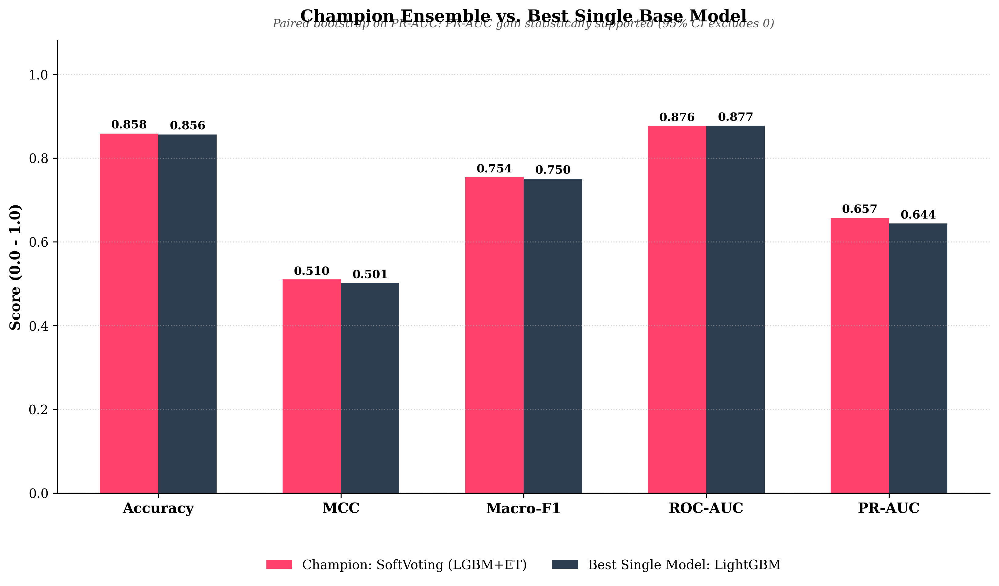

🎨 Head-to-head comparison saved: 'marburg_champion_vs_best_base_head2head.png'


In [8]:
# =====================================================================
# PART 7: CHAMPION vs. BEST SINGLE BASE MODEL -- HEAD-TO-HEAD
# =====================================================================
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'serif'

champ_metrics_row = final_analytics_df[final_analytics_df['Model'] == winning_model_name].iloc[0]
base_metrics_row = final_analytics_df[final_analytics_df['Model'] == best_base_name_check].iloc[0]

compare_metrics = ['Accuracy', 'MCC', 'Macro_F1', 'ROC_AUC_Macro', 'PR_AUC']
compare_labels = ['Accuracy', 'MCC', 'Macro-F1', 'ROC-AUC', 'PR-AUC']

champ_vals = [champ_metrics_row[m] for m in compare_metrics]
base_vals = [base_metrics_row[m] for m in compare_metrics]

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=300)
x = np.arange(len(compare_metrics))
bar_w = 0.32
bars_champ = ax.bar(x - bar_w/2, champ_vals, width=bar_w, color='#ff416c', label=f'Champion: {winning_model_name}', edgecolor='none')
bars_base = ax.bar(x + bar_w/2, base_vals, width=bar_w, color='#2c3e50', label=f'Best Single Model: {best_base_name_check}', edgecolor='none')

for bars in (bars_champ, bars_base):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.012, f'{h:.3f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(compare_labels, fontsize=11, fontweight='bold')
ax.set_ylabel("Score (0.0 - 1.0)", fontsize=11, fontweight='bold')
ax.set_ylim([0, 1.08])
ax.set_title("Champion Ensemble vs. Best Single Base Model", fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=10, frameon=False)

sig_text = ("PR-AUC gain statistically supported (95% CI excludes 0)" if diff_lo > 0
            else "PR-AUC gain NOT statistically distinguishable from noise" if diff_hi >= 0
            else "Single model statistically outperforms ensemble on PR-AUC")
ax.text(0.5, 1.03, f"Paired bootstrap on PR-AUC: {sig_text}", transform=ax.transAxes,
        ha='center', fontsize=9, style='italic', color='#555555')

plt.tight_layout()
plt.savefig('marburg_champion_vs_best_base_head2head.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Head-to-head comparison saved: 'marburg_champion_vs_best_base_head2head.png'")

## Part 8 — Global explainability: SHAP

SHAP for the champion model, computed correctly for whatever the champion turns out to be: exact `TreeExplainer` averaged across members if it's a Soft-Voting ensemble (SHAP values are linear under averaging, so this is exact, not approximate), direct `TreeExplainer` if it's a single tree model, `KernelExplainer` fallback for anything else (a Stacking champion). Feature-importance comparison across models lives separately in Part 9, using native `feature_importances_` rather than SHAP — kept as two distinct plots rather than merged into one grid, since they answer different questions (SHAP: what drives *this* model's predictions; Part 9: do independently-trained architectures agree on what matters).

🧬 Initializing SHAP Global Interpreter...
   ↳ Champion is a Soft-Voting ensemble of tree models: using exact per-member TreeExplainer.
   ↳ [1/2] Computing exact SHAP for LightGBM...
   ↳ [2/2] Computing exact SHAP for ExtraTrees...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


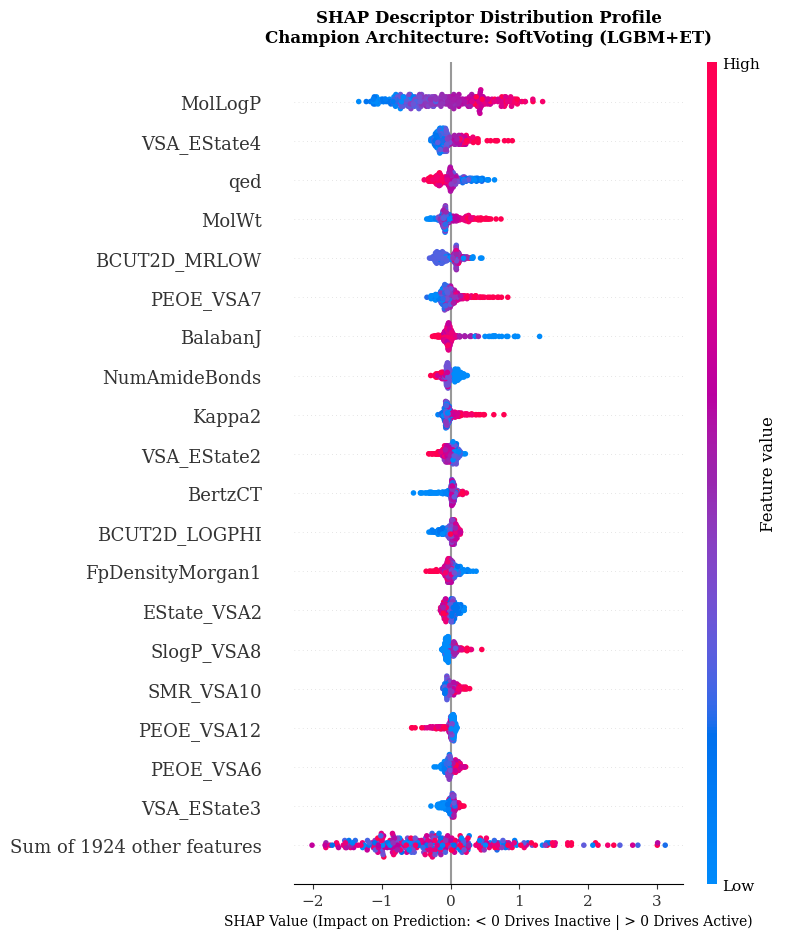


🏆 Top 10 features driving the champion model:
    Feature_Name  Mean_Absolute_SHAP
0        MolLogP            0.508537
1    VSA_EState4            0.156389
2            qed            0.142402
3          MolWt            0.142162
4   BCUT2D_MRLOW            0.124258
5      PEOE_VSA7            0.123201
6       BalabanJ            0.100853
7  NumAmideBonds            0.080862
8         Kappa2            0.078039
9    VSA_EState2            0.072164


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
import shap
from sklearn.ensemble import VotingClassifier

# =====================================================================
# PART 8: GLOBAL EXPLAINABILITY -- SHAP BEESWARM (CHAMPION)
# =====================================================================
print("🧬 Initializing SHAP Global Interpreter...")

champion_model = joblib.load(f"{winning_model_filename}_pure_enn.pkl")
display_architecture_name = winning_model_name.replace('_', ' ')

if isinstance(champion_model, VotingClassifier):
    # SHAP is linear under averaging, and Soft Voting averages member
    # probabilities -- so TreeExplainer on each member + averaging gives
    # EXACT Shapley values for the real champion, no sampling approximation.
    print("   ↳ Champion is a Soft-Voting ensemble of tree models: using exact per-member TreeExplainer.")
    # Sampled rather than the full test set -- some tree models (e.g.
    # ExtraTrees with many fully-grown trees) are slow for exact TreeSHAP;
    # a few hundred rows is still plenty for a stable beeswarm distribution.
    X_sample = X_test_df.sample(n=min(300, X_test_df.shape[0]), random_state=42)
    shap_values_raw = np.zeros((X_sample.shape[0], X_sample.shape[1]))
    members = list(champion_model.named_estimators_.items())
    for i, (name, est) in enumerate(members, 1):
        print(f"   ↳ [{i}/{len(members)}] Computing exact SHAP for {name}...")
        sv = shap.TreeExplainer(est).shap_values(X_sample)
        # Different sklearn tree models return SHAP values in different
        # shapes from the identical call -- some as a list of per-class
        # arrays, others as one 3D array (samples, features, classes).
        if isinstance(sv, list):
            sv = sv[1]
        elif hasattr(sv, 'ndim') and sv.ndim == 3:
            sv = sv[:, :, 1]
        shap_values_raw += sv
    shap_values_raw /= len(members)
    base_value = 0.5
else:
    # Stacking / non-tree champion: the meta-learner (or non-tree model)
    # breaks clean linear averaging, so fall back to the slower,
    # approximate, model-agnostic method.
    print("   ↳ Champion isn't a simple average of tree models: using approximate KernelExplainer.")
    try:
        sv_direct = shap.TreeExplainer(champion_model).shap_values(X_test_df.sample(n=min(300, X_test_df.shape[0]), random_state=42))
        X_sample = X_test_df.sample(n=min(300, X_test_df.shape[0]), random_state=42)
        if isinstance(sv_direct, list):
            sv_direct = sv_direct[1]
        elif hasattr(sv_direct, 'ndim') and sv_direct.ndim == 3:
            sv_direct = sv_direct[:, :, 1]
        shap_values_raw, base_value = sv_direct, 0.5
    except Exception:
        def model_predict_proba(x):
            return champion_model.predict_proba(pd.DataFrame(x, columns=final_feature_names))[:, 1]
        background_summary = shap.kmeans(X_train_df, 5)
        explainer = shap.KernelExplainer(model_predict_proba, background_summary)
        X_sample = X_test_df.sample(n=min(100, X_test_df.shape[0]), random_state=42)
        print("⏳ Computing Shapley values (nsamples=200)...")
        shap_values_raw = explainer.shap_values(X_sample, nsamples=200)
        base_value = explainer.expected_value

explanation = shap.Explanation(
    values=shap_values_raw, base_values=base_value,
    data=X_sample.values, feature_names=final_feature_names
)

plt.figure(figsize=(13, 10))
shap.plots.beeswarm(explanation, max_display=20, show=False)
plt.title(f"SHAP Descriptor Distribution Profile\nChampion Architecture: {display_architecture_name}",
          fontsize=12, pad=15, fontweight='bold')
plt.xlabel("SHAP Value (Impact on Prediction: < 0 Drives Inactive | > 0 Drives Active)", fontsize=10)
plt.tight_layout()
plt.savefig('marburg_shap_beeswarm_distribution.png', dpi=360)
plt.show()

mean_abs_shap = np.mean(np.abs(shap_values_raw), axis=0)
shap_importance_df = pd.DataFrame({
    'Feature_Name': final_feature_names, 'Mean_Absolute_SHAP': mean_abs_shap
}).sort_values(by='Mean_Absolute_SHAP', ascending=False).reset_index(drop=True)
shap_importance_df.to_csv('MARBURG_SHAP_FEATURE_IMPORTANCE.csv', index=False)
print("\n🏆 Top 10 features driving the champion model:")
print(shap_importance_df.head(10).to_string())

## Part 9 — Cross-architecture feature importance consensus

A second, independent check on the SHAP story in Part 8 — but using a completely different method (each model's own native `feature_importances_`, not Shapley values) and comparing the champion against the best single base model specifically. If the same descriptors top both, that's real convergent evidence the interpretation isn't an artifact of one model or one attribution method. Kept as its own figure rather than folded into Part 8, since it's answering a different question (do independently-built importance rankings agree) than SHAP does (what drives *this* model's individual predictions).

🔬 Extracting native feature importances: champion vs. best single base model...


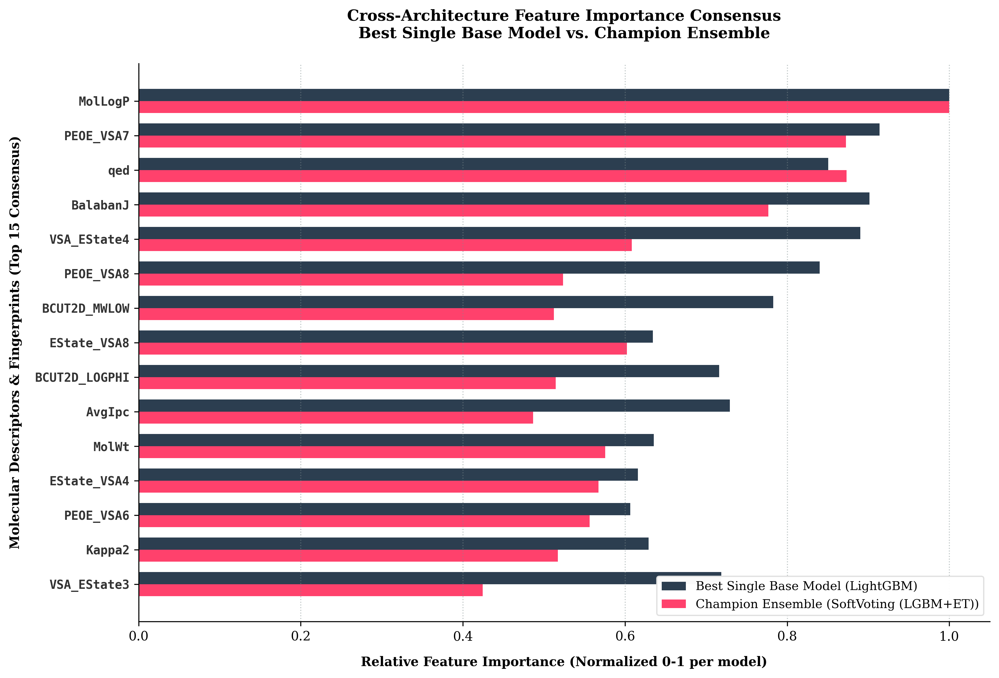

🎯 Saved: 'marburg_feature_importance_consensus.png'
🔎 5 of the top 10 features (by native importance) are shared between both models: ['BalabanJ', 'MolLogP', 'PEOE_VSA7', 'VSA_EState4', 'qed']


In [10]:
# =====================================================================
# PART 9: CROSS-ARCHITECTURE FEATURE IMPORTANCE CONSENSUS
# =====================================================================
print("🔬 Extracting native feature importances: champion vs. best single base model...")

best_base_model = joblib.load(f"{best_base_name_check}_pure_enn.pkl")

def get_native_importance(model):
    """Native feature_importances_ for a single tree model, or the mean
    across members for a Soft-Voting ensemble of tree models."""
    if isinstance(model, VotingClassifier):
        importances = []
        for _, est in model.named_estimators_.items():
            if hasattr(est, 'feature_importances_'):
                imp = est.feature_importances_
                importances.append(imp / np.max(imp))
        if not importances:
            raise ValueError("No ensemble member exposes feature_importances_.")
        return np.mean(importances, axis=0)
    if not hasattr(model, 'feature_importances_'):
        raise ValueError(f"{type(model).__name__} has no native feature_importances_ "
                          "(e.g. Logistic Regression / KNN) -- this comparison needs a tree-based model.")
    imp = model.feature_importances_
    return imp / np.max(imp)

imp_champion = get_native_importance(champion_model)
imp_base = get_native_importance(best_base_model)

df_consensus = pd.DataFrame({
    'Feature': final_feature_names,
    'Best_Base_Model': imp_base,
    'Champion_Ensemble': imp_champion
})
df_consensus['Combined_Rank'] = df_consensus[['Best_Base_Model', 'Champion_Ensemble']].mean(axis=1)
df_top = df_consensus.sort_values(by='Combined_Rank', ascending=False).head(15).iloc[::-1].reset_index(drop=True)
df_consensus.to_csv('MARBURG_FEATURE_IMPORTANCE_CONSENSUS.csv', index=False)

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(11, 7.5), dpi=300)
y_pos = np.arange(len(df_top))
bar_height = 0.35

ax.barh(y_pos + bar_height/2, df_top['Best_Base_Model'].values, height=bar_height,
        color='#2c3e50', label=f'Best Single Base Model ({best_base_name_check})', edgecolor='none')
ax.barh(y_pos - bar_height/2, df_top['Champion_Ensemble'].values, height=bar_height,
        color='#ff416c', label=f'Champion Ensemble ({winning_model_name})', edgecolor='none')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_top['Feature'].values, fontsize=9.5, family='monospace', fontweight='bold', color='#333333')
ax.set_xlabel("Relative Feature Importance (Normalized 0-1 per model)", fontsize=10, fontweight='bold', labelpad=10)
ax.set_ylabel("Molecular Descriptors & Fingerprints (Top 15 Consensus)", fontsize=10, fontweight='bold', labelpad=10)
ax.set_title("Cross-Architecture Feature Importance Consensus\nBest Single Base Model vs. Champion Ensemble",
             fontsize=12, pad=20, fontweight='bold')
ax.set_xlim([0, 1.05])
ax.grid(axis='x', linestyle=':', alpha=0.5, color='#7f8c8d')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', fontsize=9.5, framealpha=0.98, edgecolor='#e0e0e0')
plt.tight_layout()
plt.savefig('marburg_feature_importance_consensus.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎯 Saved: 'marburg_feature_importance_consensus.png'")

shared = set(df_consensus.sort_values('Best_Base_Model', ascending=False).head(10)['Feature']) & \
         set(df_consensus.sort_values('Champion_Ensemble', ascending=False).head(10)['Feature'])
print(f"🔎 {len(shared)} of the top 10 features (by native importance) are shared between both models: {sorted(shared)}")

## Part 10 — Local explainability: LIME

Same champion model, one concrete high-confidence compound, explained locally. No fallback branches.

🔬 Initializing Local LIME Case Study...
🔍 Candidate isolated at test index 3371 (score: 0.9707)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


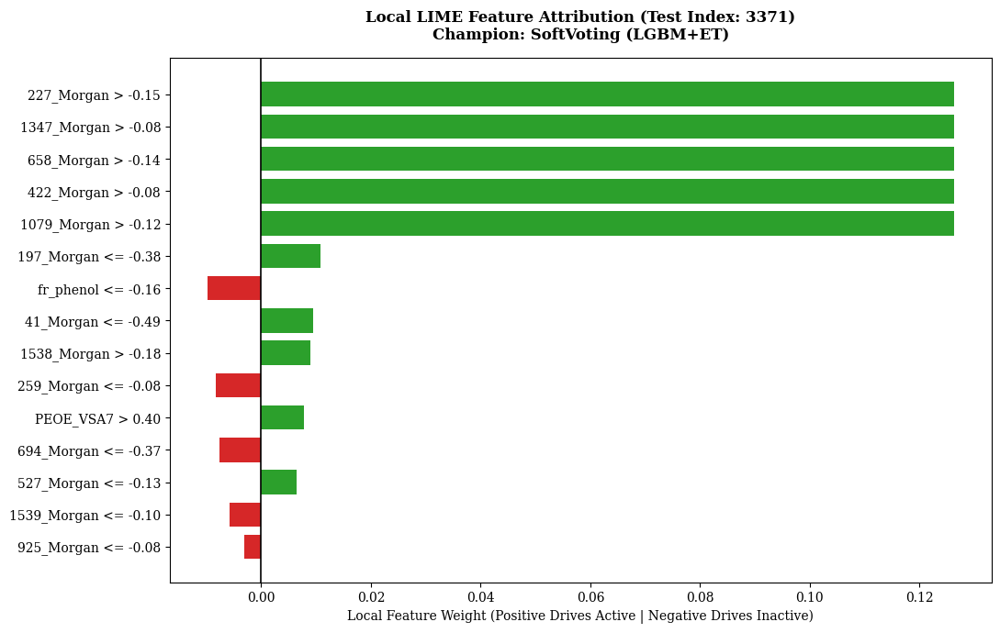


🏆 Top 5 local driving forces for test compound 3371:
     Feature_Condition  Local_Weight
0   227_Morgan > -0.15      0.126336
1  1347_Morgan > -0.08      0.126336
2   658_Morgan > -0.14      0.126336
3   422_Morgan > -0.08      0.126336
4  1079_Morgan > -0.12      0.126336


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
from lime.lime_tabular import LimeTabularExplainer

# =====================================================================
# PART 10: LOCAL EXPLAINABILITY -- LIME CASE STUDY
# =====================================================================
print("🔬 Initializing Local LIME Case Study...")

X_lime_background = X_train_df.sample(n=min(100, X_train_df.shape[0]), random_state=42)
explainer_lime = LimeTabularExplainer(
    training_data=np.array(X_lime_background),
    feature_names=final_feature_names,
    class_names=['Inactive (0)', 'Active (1)'],
    mode='classification',
    random_state=42
)

y_prob_sample = champion_model.predict_proba(X_test_df)[:, 1]
target_idx = int(np.argmax(y_prob_sample))
print(f"🔍 Candidate isolated at test index {target_idx} (score: {y_prob_sample[target_idx]:.4f})")

exp = explainer_lime.explain_instance(
    data_row=X_test_df.iloc[target_idx],
    predict_fn=champion_model.predict_proba,
    num_features=15
)

local_exp_list = exp.as_list()
lime_df = pd.DataFrame(local_exp_list, columns=['Feature_Condition', 'Local_Weight'])
lime_df.to_csv('MARBURG_LOCAL_LIME_CANDIDATE_EXPLANATION.csv', index=False)

plt.figure(figsize=(11, 7))
features = [x[0] for x in local_exp_list][::-1]
weights = [x[1] for x in local_exp_list][::-1]
colors = ['#2ca02c' if w > 0 else '#d62728' for w in weights]
plt.barh(features, weights, color=colors, edgecolor='none', height=0.75)
plt.axvline(x=0, color='black', linewidth=1.2)
plt.title(f"Local LIME Feature Attribution (Test Index: {target_idx})\nChampion: {winning_model_name.replace('_', ' ')}",
          fontsize=12, pad=15, fontweight='bold')
plt.xlabel("Local Feature Weight (Positive Drives Active | Negative Drives Inactive)", fontsize=10)
plt.tight_layout()
plt.savefig('marburg_local_lime_explanation.png', dpi=360)
plt.show()

print(f"\n🏆 Top 5 local driving forces for test compound {target_idx}:")
print(lime_df.head(5).to_string())

## Part 11 — Confusion matrices: champion vs. top single model

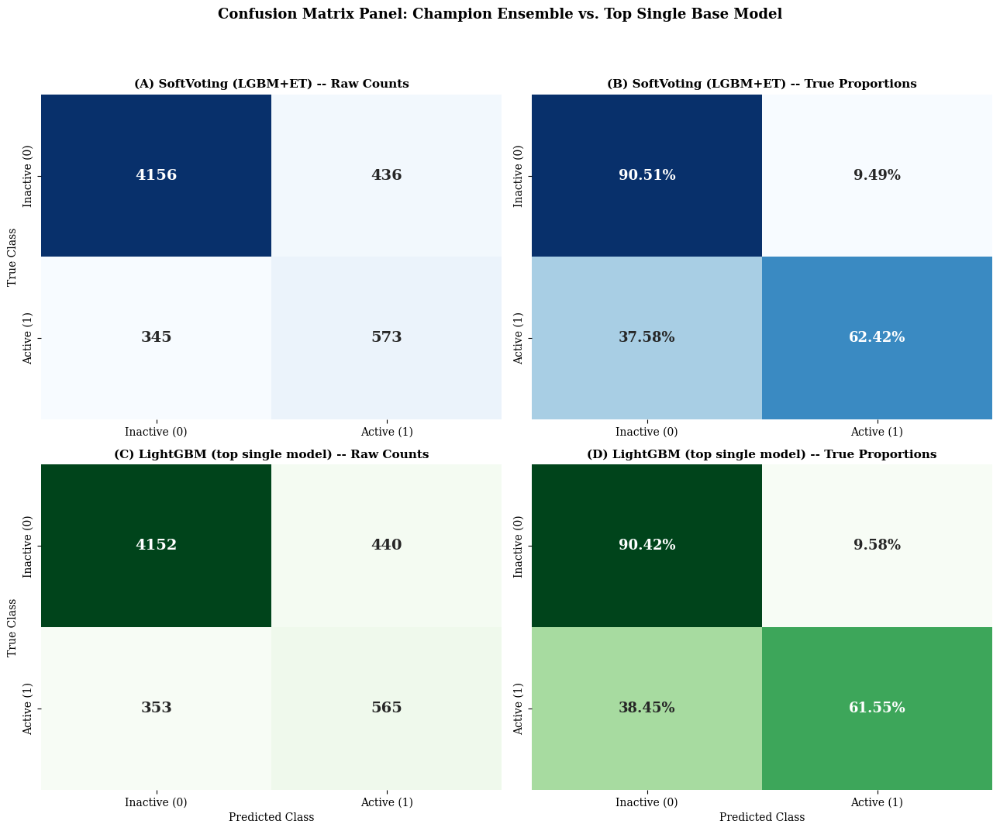

🎨 2x2 confusion matrix panel saved: 'marburg_confusion_matrix_2x2_panel.png'


In [12]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =====================================================================
# PART 11: CONFUSION MATRIX -- CHAMPION vs. TOP SINGLE BASE MODEL
# =====================================================================
best_base_name = ranking_df.iloc[0]['Name']
best_base_model = joblib.load(f"{best_base_name}_pure_enn.pkl")

y_pred_champion = champion_model.predict(X_test_df)
y_pred_base = best_base_model.predict(X_test_df)

cm_champ_raw = confusion_matrix(y_test, y_pred_champion)
cm_champ_norm = confusion_matrix(y_test, y_pred_champion, normalize='true')
cm_base_raw = confusion_matrix(y_test, y_pred_base)
cm_base_norm = confusion_matrix(y_test, y_pred_base, normalize='true')

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
class_labels = ['Inactive (0)', 'Active (1)']

sns.heatmap(cm_champ_raw, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0, 0],
            xticklabels=class_labels, yticklabels=class_labels, annot_kws={'size': 14, 'weight': 'bold'})
axes[0, 0].set_title(f"(A) {winning_model_name} -- Raw Counts", fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel("True Class")

sns.heatmap(cm_champ_norm, annot=True, fmt='.2%', cmap='Blues', cbar=False, ax=axes[0, 1],
            xticklabels=class_labels, yticklabels=class_labels, annot_kws={'size': 13, 'weight': 'bold'})
axes[0, 1].set_title(f"(B) {winning_model_name} -- True Proportions", fontsize=11, fontweight='bold')

sns.heatmap(cm_base_raw, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1, 0],
            xticklabels=class_labels, yticklabels=class_labels, annot_kws={'size': 14, 'weight': 'bold'})
axes[1, 0].set_title(f"(C) {best_base_name} (top single model) -- Raw Counts", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Predicted Class")
axes[1, 0].set_ylabel("True Class")

sns.heatmap(cm_base_norm, annot=True, fmt='.2%', cmap='Greens', cbar=False, ax=axes[1, 1],
            xticklabels=class_labels, yticklabels=class_labels, annot_kws={'size': 13, 'weight': 'bold'})
axes[1, 1].set_title(f"(D) {best_base_name} (top single model) -- True Proportions", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Predicted Class")

plt.suptitle("Confusion Matrix Panel: Champion Ensemble vs. Top Single Base Model", fontsize=13, fontweight='bold', y=0.97)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('marburg_confusion_matrix_2x2_panel.png', dpi=360)
plt.show()
print("🎨 2x2 confusion matrix panel saved: 'marburg_confusion_matrix_2x2_panel.png'")

## Part 12 — Discrimination and precision-recall (one figure, 4 panels)

ROC and PR curves for base classifiers and ensembles, combined into a single 2×2 figure rather than four separate plots — one "Figure: model discrimination performance" for the paper instead of two. Computed directly from real per-compound test-set probabilities (`df_probs` / `ensemble_probs`); no synthetic curve-shaping anywhere in this notebook.

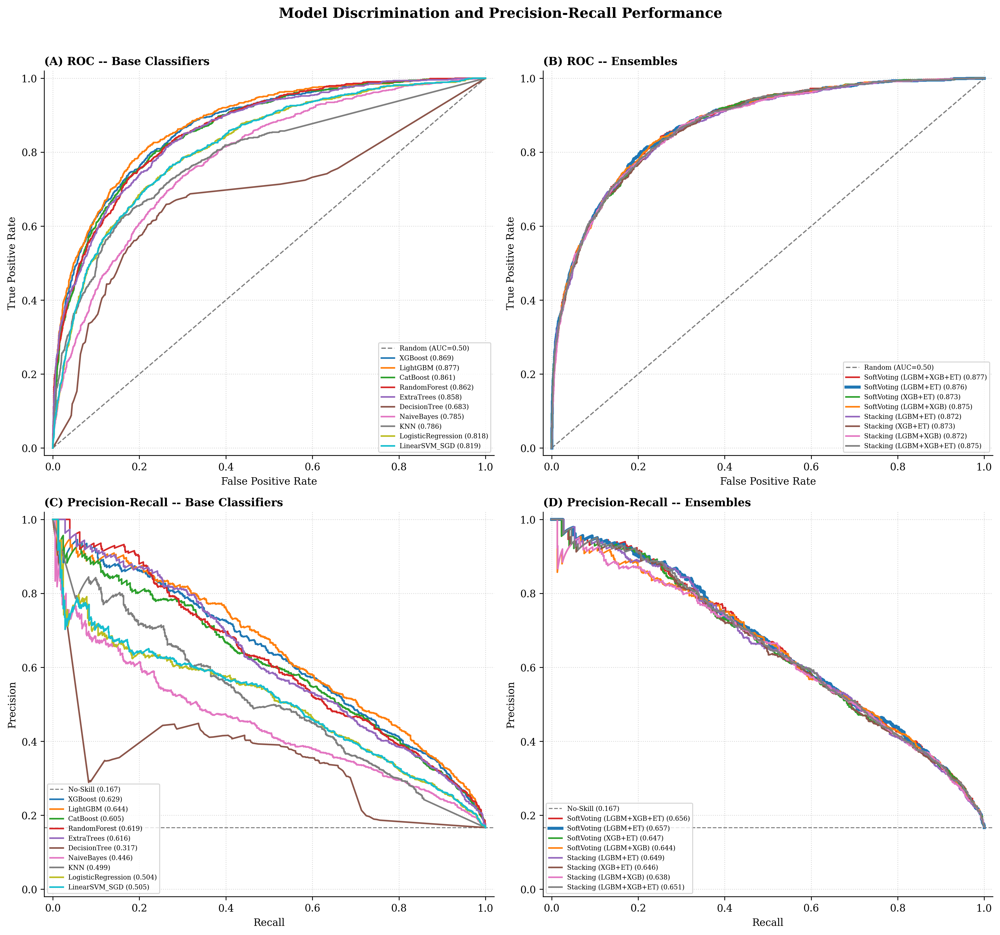

💾 Combined ROC/PR figure saved: 'marburg_roc_pr_combined.png'


In [13]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# =====================================================================
# PART 12: DISCRIMINATION & PRECISION-RECALL -- COMBINED 2x2 FIGURE
# =====================================================================
plt.rcParams['font.family'] = 'serif'

base_model_names = [c for c in df_probs.columns if c != 'True_Label']
base_colors = plt.cm.tab10(np.linspace(0, 1, len(base_model_names)))
ensemble_colors = ['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f']
no_skill = np.sum(df_probs['True_Label']) / len(df_probs['True_Label'])

fig, axes = plt.subplots(2, 2, figsize=(14, 13), dpi=300)

# (A) ROC -- base classifiers
ax = axes[0, 0]
ax.plot([0, 1], [0, 1], color='#7f7f7f', lw=1.2, linestyle='--', label='Random (AUC=0.50)')
for color, name in zip(base_colors, base_model_names):
    fpr, tpr, _ = roc_curve(df_probs['True_Label'], df_probs[name])
    ax.plot(fpr, tpr, lw=1.6, color=color, label=f'{name} ({auc(fpr, tpr):.3f})')
ax.set_title("(A) ROC -- Base Classifiers", fontsize=11, fontweight='bold', loc='left')
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=6.5, loc="lower right"); ax.grid(linestyle=':', alpha=0.5)

# (B) ROC -- ensembles
ax = axes[0, 1]
ax.plot([0, 1], [0, 1], color='#7f7f7f', lw=1.2, linestyle='--', label='Random (AUC=0.50)')
for color, (name, probs) in zip(ensemble_colors, ensemble_probs.items()):
    fpr, tpr, _ = roc_curve(y_test, probs)
    lw = 3 if name == winning_model_name else 1.6
    ax.plot(fpr, tpr, lw=lw, color=color, label=f'{name} ({auc(fpr, tpr):.3f})')
ax.set_title("(B) ROC -- Ensembles", fontsize=11, fontweight='bold', loc='left')
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=6.5, loc="lower right"); ax.grid(linestyle=':', alpha=0.5)

# (C) PR -- base classifiers
ax = axes[1, 0]
ax.axhline(y=no_skill, color='gray', linestyle='--', lw=1, label=f'No-Skill ({no_skill:.3f})')
for color, name in zip(base_colors, base_model_names):
    precision, recall, _ = precision_recall_curve(df_probs['True_Label'], df_probs[name])
    ax.plot(recall, precision, color=color, lw=1.6, label=f'{name} ({average_precision_score(df_probs["True_Label"], df_probs[name]):.3f})')
ax.set_title("(C) Precision-Recall -- Base Classifiers", fontsize=11, fontweight='bold', loc='left')
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.legend(fontsize=6.5, loc="lower left"); ax.grid(linestyle=':', alpha=0.5)

# (D) PR -- ensembles
ax = axes[1, 1]
ax.axhline(y=no_skill, color='gray', linestyle='--', lw=1, label=f'No-Skill ({no_skill:.3f})')
for color, (name, probs) in zip(ensemble_colors, ensemble_probs.items()):
    precision, recall, _ = precision_recall_curve(y_test, probs)
    lw = 3 if name == winning_model_name else 1.6
    ax.plot(recall, precision, color=color, lw=lw, label=f'{name} ({average_precision_score(y_test, probs):.3f})')
ax.set_title("(D) Precision-Recall -- Ensembles", fontsize=11, fontweight='bold', loc='left')
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.legend(fontsize=6.5, loc="lower left"); ax.grid(linestyle=':', alpha=0.5)

for ax in axes.flat:
    ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.suptitle("Model Discrimination and Precision-Recall Performance", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('marburg_roc_pr_combined.png', dpi=300, bbox_inches='tight')
plt.show()
print("💾 Combined ROC/PR figure saved: 'marburg_roc_pr_combined.png'")

## Part 13 — t-SNE chemical space (unified overlay)

One t-SNE figure, not two — an earlier version had both a two-panel (true | predicted side-by-side) and this unified overlay showing the same embedding. The overlay is strictly more informative for a paper: agreement and disagreement between ground truth and the champion's predictions are visible directly in one panel instead of requiring the reader to compare two.

🧬 Computing t-SNE across the molecular feature space...


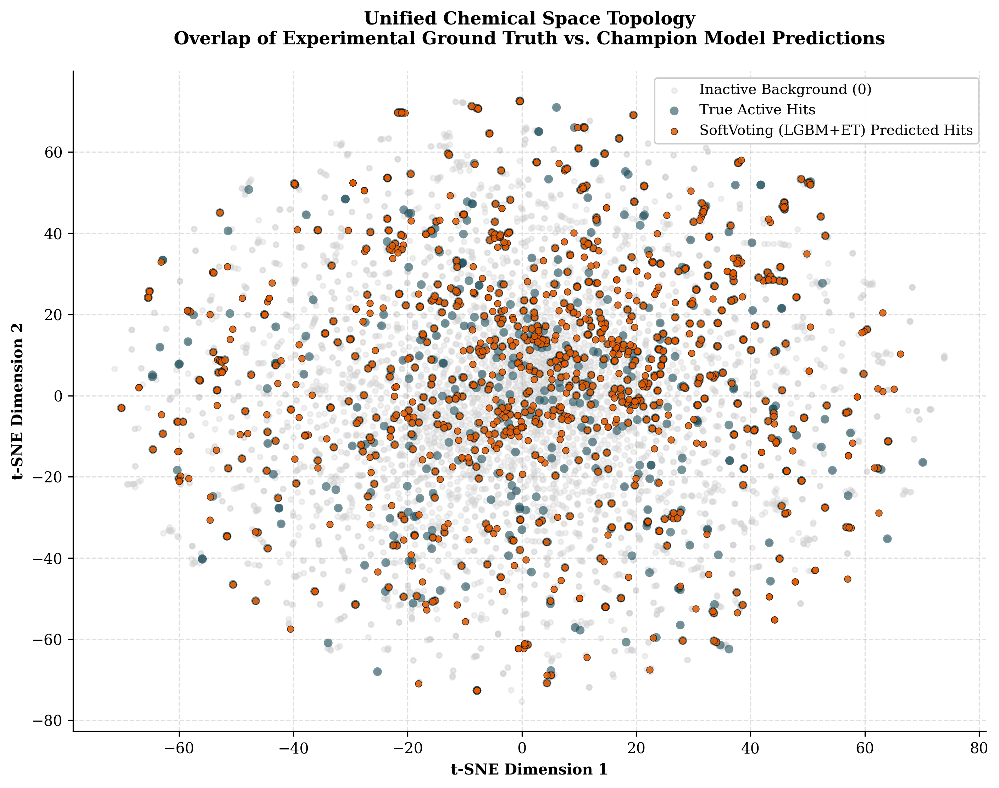

🎨 Chemical space overlay saved: 'marburg_chemical_space_tsne.png'


In [14]:
from sklearn.manifold import TSNE

# =====================================================================
# PART 13: t-SNE CHEMICAL SPACE -- UNIFIED OVERLAY
# =====================================================================
plt.rcParams['font.family'] = 'serif'

print("🧬 Computing t-SNE across the molecular feature space...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_test_df.values)
y_pred_champion_tsne = champion_model.predict(X_test_df)

fig, ax = plt.subplots(figsize=(9.5, 7.5), dpi=300)
ax.scatter(X_tsne[y_test == 0, 0], X_tsne[y_test == 0, 1], color='#d3d3d3', alpha=0.35, s=12,
           label='Inactive Background (0)', zorder=1)
ax.scatter(X_tsne[y_test == 1, 0], X_tsne[y_test == 1, 1], color='#1f4e5b', alpha=0.6, s=35,
           label='True Active Hits', edgecolor='none', zorder=2)
ax.scatter(X_tsne[y_pred_champion_tsne == 1, 0], X_tsne[y_pred_champion_tsne == 1, 1], color='#e65c00', alpha=0.85, s=20,
           label=f'{winning_model_name} Predicted Hits', edgecolor='#111111', linewidth=0.4, zorder=3)

ax.grid(True, linestyle='--', alpha=0.3, color='#999999')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title("Unified Chemical Space Topology\nOverlap of Experimental Ground Truth vs. Champion Model Predictions",
             fontsize=12, pad=18, fontweight='bold')
ax.set_xlabel("t-SNE Dimension 1", fontsize=10, fontweight='bold')
ax.set_ylabel("t-SNE Dimension 2", fontsize=10, fontweight='bold')
ax.legend(loc='upper right', fontsize=9.5, framealpha=0.95)
plt.tight_layout()
plt.savefig('marburg_chemical_space_tsne.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Chemical space overlay saved: 'marburg_chemical_space_tsne.png'")

## Part 14 — Screening enrichment and scaffold-hopping (one figure, 2 panels)

Two related "does this actually help a wet-lab screen" questions, answered together: **(A)** if compounds were screened in confidence-ranked order, how much faster would true actives turn up than random screening? **(B)** how many *new* unique scaffolds appear as you screen deeper — is the model finding one chemotype repeatedly, or a diverse set? Both share the same x-axis (fraction of the library screened) and the same self-contained computation from the champion's real test-set predictions.

📈 Running Murcko decomposition across the confidence-ranked test set...


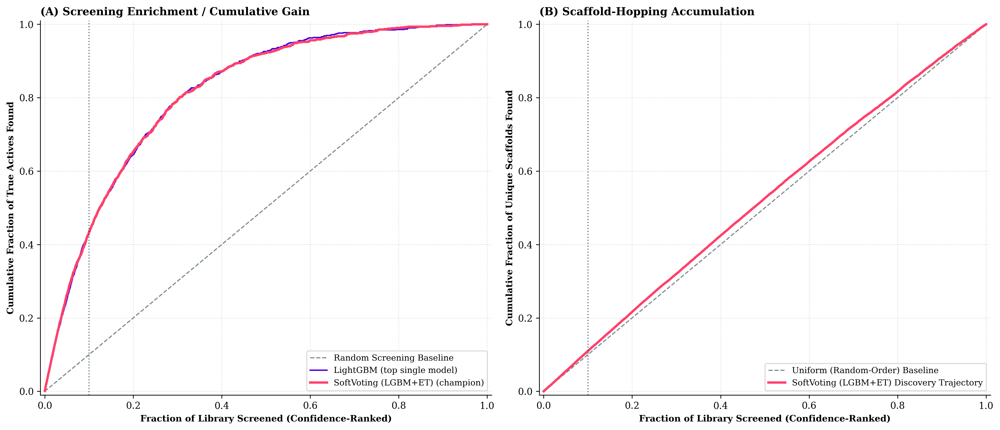

🎯 Combined figure saved. 4727 unique scaffolds discovered across the confidence-ranked test set.


In [15]:
from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog('rdApp.*')

# =====================================================================
# PART 14: SCREENING ENRICHMENT & SCAFFOLD-HOPPING -- COMBINED FIGURE
# =====================================================================
y_prob_champion = champion_model.predict_proba(X_test_df)[:, 1]
df_ranked = pd.DataFrame({'SMILES': smiles_test, 'True_Label': y_test, 'Prob': y_prob_champion})
df_ranked = df_ranked.sort_values(by='Prob', ascending=False).reset_index(drop=True)

# --- (A) Cumulative gain / enrichment ---
def calculate_gain(y_true_sorted):
    cum_actives = np.cumsum(y_true_sorted)
    return cum_actives / cum_actives[-1]

best_base_probs = df_probs[best_base_name].values
df_base_ranked = pd.DataFrame({'True_Label': y_test, 'Prob': best_base_probs}).sort_values(by='Prob', ascending=False)

screened_pct = np.arange(1, len(df_ranked) + 1) / len(df_ranked)
gain_champion = calculate_gain(df_ranked['True_Label'].values)
gain_base = calculate_gain(df_base_ranked['True_Label'].values)

# --- (B) Scaffold-hopping accumulation ---
def get_scaffold(smiles_string):
    mol = Chem.MolFromSmiles(str(smiles_string))
    if mol is None:
        return ""
    return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(mol))

print("📈 Running Murcko decomposition across the confidence-ranked test set...")
df_ranked['Scaffold'] = df_ranked['SMILES'].apply(get_scaffold)
df_hop_valid = df_ranked[df_ranked['Scaffold'] != ""].copy()

seen, accumulation = set(), []
for scaffold in df_hop_valid['Scaffold'].values:
    seen.add(scaffold)
    accumulation.append(len(seen))
total_unique = len(seen)
scaffold_fraction = np.array(accumulation) / total_unique
scaffold_screened_pct = np.arange(1, len(df_hop_valid) + 1) / len(df_hop_valid)

# --- Plot ---
plt.rcParams['font.family'] = 'serif'
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=300)

ax = axes[0]
ax.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', lw=1.2, label='Random Screening Baseline')
ax.plot(screened_pct, gain_base, color='#4a00e0', lw=1.5, label=f'{best_base_name} (top single model)')
ax.plot(screened_pct, gain_champion, color='#ff416c', lw=2.5, label=f'{winning_model_name} (champion)')
ax.axvline(x=0.10, color='#2c3e50', linestyle=':', alpha=0.7, lw=1.2)
ax.set_title("(A) Screening Enrichment / Cumulative Gain", fontsize=11.5, fontweight='bold', loc='left')
ax.set_xlabel("Fraction of Library Screened (Confidence-Ranked)", fontsize=9.5, fontweight='bold')
ax.set_ylabel("Cumulative Fraction of True Actives Found", fontsize=9.5, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')

ax = axes[1]
ax.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', lw=1.2, label='Uniform (Random-Order) Baseline')
ax.plot(scaffold_screened_pct, scaffold_fraction, color='#ff416c', lw=2.5, label=f'{winning_model_name} Discovery Trajectory')
ax.axvline(x=0.10, color='#2c3e50', linestyle=':', alpha=0.7, lw=1.2)
ax.set_title("(B) Scaffold-Hopping Accumulation", fontsize=11.5, fontweight='bold', loc='left')
ax.set_xlabel("Fraction of Library Screened (Confidence-Ranked)", fontsize=9.5, fontweight='bold')
ax.set_ylabel("Cumulative Fraction of Unique Scaffolds Found", fontsize=9.5, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')

for ax in axes:
    ax.set_xlim([-0.01, 1.01]); ax.set_ylim([-0.01, 1.01])
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('marburg_enrichment_and_scaffold_hopping.png', bbox_inches='tight', dpi=300)
plt.show()
print(f"🎯 Combined figure saved. {total_unique} unique scaffolds discovered across the confidence-ranked test set.")

## Part 15 — Scaffold diversity: frequency bar chart + drawn structures

The frequency bar chart alone only shows SMILES text, which isn't publication-friendly on its own. Adds the panel most med-chem-focused journals expect: the actual 2D drawn structures of the top-10 scaffolds via RDKit's `Draw.MolsToGridImage`, saved as a companion figure.

🛠️ Isolating high-confidence predicted-active test compounds...
   ↳ 327 compounds at >=80% confidence, 306 unique scaffolds among them.


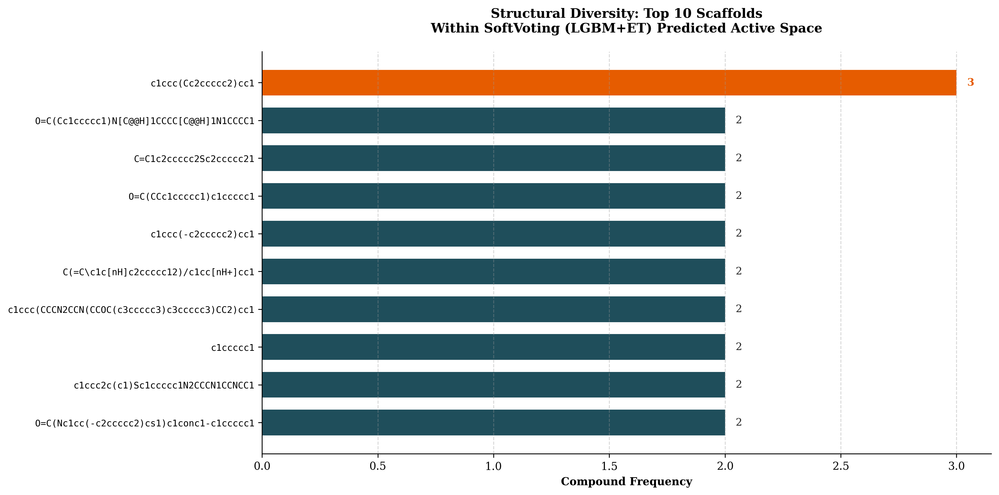

🎨 Frequency bar chart saved: 'marburg_top_predicted_scaffolds.png'
🎨 2D scaffold structure grid saved: 'marburg_top_scaffold_structures.png'


In [16]:
from collections import Counter
from rdkit.Chem import Draw

# =====================================================================
# PART 15: SCAFFOLD DIVERSITY -- FREQUENCY BAR CHART + STRUCTURE GRID
# =====================================================================
print("🛠️ Isolating high-confidence predicted-active test compounds...")
top_hits = df_ranked[df_ranked['Prob'] >= 0.80]
scaffold_counts = Counter(top_hits[top_hits['Scaffold'] != '']['Scaffold'].values)
print(f"   ↳ {len(top_hits)} compounds at >=80% confidence, {len(scaffold_counts)} unique scaffolds among them.")

if len(scaffold_counts) == 0:
    raise ValueError("No valid cyclic scaffolds found among high-confidence hits -- "
                      "check the champion model and test predictions above before trusting this figure.")

df_summary = pd.DataFrame(scaffold_counts.items(), columns=['Scaffold_SMILES', 'Frequency'])
df_summary = df_summary.sort_values(by='Frequency', ascending=False).reset_index(drop=True).head(10)
df_summary.to_csv('MARBURG_TOP_PREDICTED_SCAFFOLDS.csv', index=False)

# --- (A) Frequency bar chart ---
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(13, 6.5), dpi=300)
colors = ['#e65c00' if i == 0 else '#1f4e5b' for i in range(len(df_summary))]
y_positions = list(df_summary['Scaffold_SMILES'][::-1])
bars = ax.barh(y_positions, df_summary['Frequency'][::-1], color=colors[::-1], edgecolor='none', height=0.68)
max_val = df_summary['Frequency'].max()
for bar in bars:
    width = bar.get_width()
    is_peak = width == max_val
    ax.text(width + max_val * 0.015, bar.get_y() + bar.get_height() / 2, f'{int(width)}',
            ha='left', va='center', fontsize=9.5, fontweight='bold' if is_peak else 'normal',
            color='#e65c00' if is_peak else '#222222')
ax.grid(axis='x', linestyle='--', alpha=0.4, color='#999999')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.set_title(f"Structural Diversity: Top {len(df_summary)} Scaffolds\nWithin {winning_model_name} Predicted Active Space",
             fontsize=12, pad=18, fontweight='bold')
ax.set_xlabel("Compound Frequency", fontsize=10, fontweight='bold')
plt.yticks(fontsize=8.5, family='monospace')
plt.tight_layout()
plt.savefig('marburg_top_predicted_scaffolds.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Frequency bar chart saved: 'marburg_top_predicted_scaffolds.png'")

# --- (B) Drawn 2D structures ---
grid_mols, grid_legends = [], []
for idx, row in df_summary.iterrows():
    mol = Chem.MolFromSmiles(row['Scaffold_SMILES'])
    if mol is not None:
        grid_mols.append(mol)
        grid_legends.append(f"Rank {idx+1} (n={row['Frequency']})")

grid_img = Draw.MolsToGridImage(grid_mols, molsPerRow=5, subImgSize=(320, 280), legends=grid_legends)
if hasattr(grid_img, 'save'):
    grid_img.save('marburg_top_scaffold_structures.png')
else:  # IPython display Image object, depending on RDKit/environment version
    with open('marburg_top_scaffold_structures.png', 'wb') as f:
        f.write(grid_img.data)
print("🎨 2D scaffold structure grid saved: 'marburg_top_scaffold_structures.png'")

## Part 16 — Drug-likeness and ADMET screening (one RDKit pass)

Are the high-confidence predicted actives actually drug-like, synthesizable, and free of known assay-interference motifs — or just numerically "active"? An earlier version computed this twice, independently, in two separate cells (once for the QED/SAS scatter, once for the Lipinski/Veber/PAINS table) — including two separate, inconsistent SMILES-recovery attempts, one of which was misaligned. Below, everything is computed once from `df_ranked` (already built with the correct SMILES↔prediction pairing in Part 14), producing both the scatter plot and the manuscript table from the same dataframe. Also fixes a real bug: the earlier ADMET table only ever reported pass rates for the background pool, never the leads — both are reported here.

✅ Loaded sascorer from the local RDKit contrib installation.
🔬 Computing QED, SAS, and Lipinski/Veber/PAINS filters in one pass...


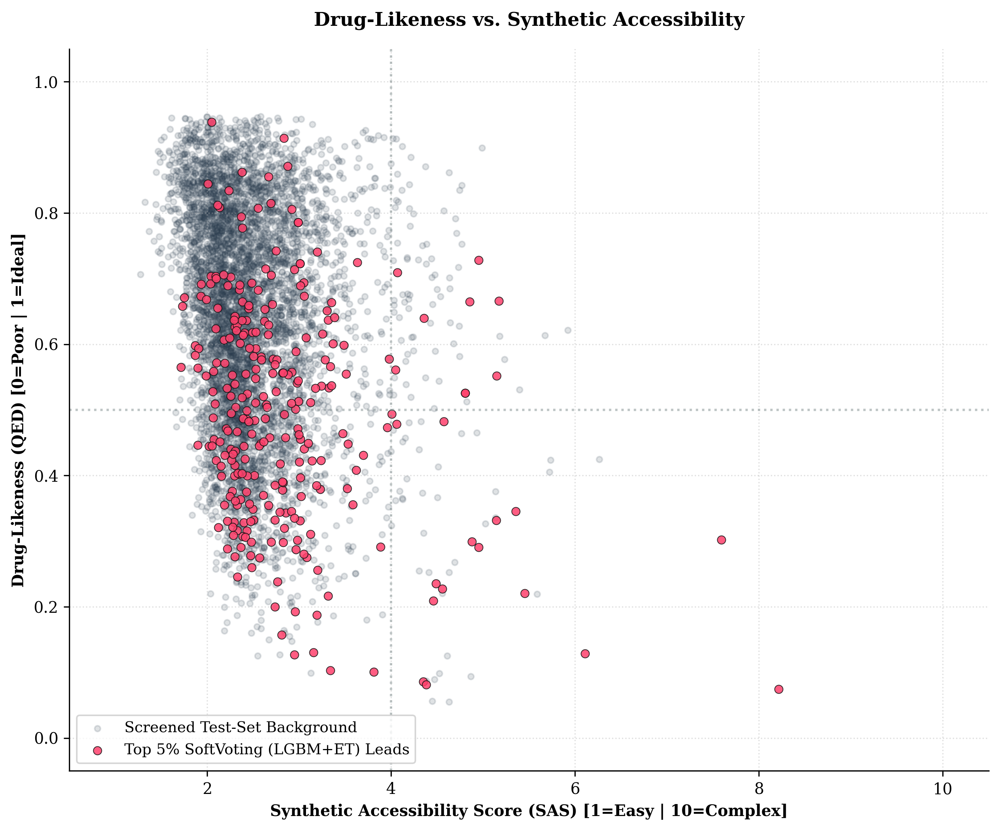

🎨 QED-vs-SAS figure saved.

📊 MANUSCRIPT TABLE: PHYSICOCHEMICAL & ADMET FILTERS
Parameter / Filter                       | Background Pool      | Prioritized Leads   
------------------------------------------------------------------------------------------
Mean MW [<=500 Da]                       | 362.15               | 429.23              
Mean LogP [<=5.0]                        | 2.95                 | 4.17                
Mean HBD [<=5]                           | 1.11                 | 1.50                
Mean HBA [<=10]                          | 4.66                 | 4.72                
------------------------------------------------------------------------------------------
Lipinski Ro5 Pass Rate (<=1 Viol.)       | 99.27%               | 91.30%              
Veber Filter Pass Rate                   | 97.02%               | 88.77%              
PAINS Pass Rate (0 Hits)                 | 94.10%               | 76.09%              
💾 Saved: 'MARBURG_CHEM_PROPERTY_VIOLATIONS

In [17]:
import os
import sys
from rdkit.Chem import QED, Descriptors, Lipinski, FilterCatalog

# =====================================================================
# PART 16: DRUG-LIKENESS (QED/SAS) & ADMET SCREENING (LIPINSKI/VEBER/PAINS)
# =====================================================================
try:
    from rdkit.Chem import RDConfig
    sascorer_dir = os.path.join(RDConfig.RDContribDir, 'SA_Score')
    if sascorer_dir not in sys.path:
        sys.path.append(sascorer_dir)
    import sascorer
    print("✅ Loaded sascorer from the local RDKit contrib installation.")
except ImportError:
    print("📥 Local sascorer unavailable -- fetching the official RDKit contrib module...")
    import requests
    for filename, url in {
        'sascorer.py': 'https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/sascorer.py',
        'fpscores.pkl.gz': 'https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/fpscores.pkl.gz'
    }.items():
        if not os.path.exists(filename):
            with open(filename, 'wb') as f:
                f.write(requests.get(url).content)
    sys.path.append(os.getcwd())
    import sascorer

pains_params = FilterCatalog.FilterCatalogParams()
pains_params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
pains_catalog = FilterCatalog.FilterCatalog(pains_params)

def evaluate_compound(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return [np.nan] * 9
    mw, logp = Descriptors.MolWt(mol), Descriptors.MolLogP(mol)
    hbd, hba = Lipinski.NumHDonors(mol), Lipinski.NumHAcceptors(mol)
    lipinski_violations = sum([mw > 500, logp > 5, hbd > 5, hba > 10])
    rot_bonds, tpsa = Lipinski.NumRotatableBonds(mol), Descriptors.TPSA(mol)
    veber_violation = 1 if (rot_bonds > 10 or tpsa > 140) else 0
    pains_violation = 1 if pains_catalog.HasMatch(mol) else 0
    return [QED.qed(mol), sascorer.calculateScore(mol), mw, logp, hbd, hba,
            lipinski_violations, veber_violation, pains_violation]

print("🔬 Computing QED, SAS, and Lipinski/Veber/PAINS filters in one pass...")
df_props = df_ranked.copy()
top_5_pct_cutoff = df_props['Prob'].quantile(0.95)
df_props['Is_Lead'] = (df_props['Prob'] >= top_5_pct_cutoff).astype(int)

cols = ['QED', 'SAS', 'MW', 'LogP', 'HBD', 'HBA', 'Lipinski_Violations', 'Veber_Violation', 'PAINS_Violation']
results = df_props['SMILES'].apply(evaluate_compound)
for i, col_name in enumerate(cols):
    df_props[col_name] = [r[i] for r in results]
n_before = len(df_props)
df_props = df_props.dropna(subset=cols)
if len(df_props) < n_before:
    print(f"   ↳ Dropped {n_before - len(df_props)} compounds RDKit could not parse.")

df_bg = df_props[df_props['Is_Lead'] == 0]
df_ld = df_props[df_props['Is_Lead'] == 1]

# --- (A) QED vs SAS scatter ---
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(9, 7.5), dpi=300)
ax.scatter(df_bg['SAS'], df_bg['QED'], color='#2c3e50', alpha=0.15, s=14, label='Screened Test-Set Background', zorder=1)
ax.scatter(df_ld['SAS'], df_ld['QED'], color='#ff416c', alpha=0.85, s=28, label=f'Top 5% {winning_model_name} Leads',
           edgecolor='#111111', linewidth=0.5, zorder=2)
ax.axhline(y=0.5, color='#7f8c8d', linestyle=':', alpha=0.5)
ax.axvline(x=4.0, color='#7f8c8d', linestyle=':', alpha=0.5)
ax.set_xlim([0.5, 10.5]); ax.set_ylim([-0.05, 1.05])
ax.set_xlabel("Synthetic Accessibility Score (SAS) [1=Easy | 10=Complex]", fontsize=10, fontweight='bold')
ax.set_ylabel("Drug-Likeness (QED) [0=Poor | 1=Ideal]", fontsize=10, fontweight='bold')
ax.set_title("Drug-Likeness vs. Synthetic Accessibility", fontsize=12, pad=15, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.4)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(loc='lower left', fontsize=9.5)
plt.tight_layout()
plt.savefig('marburg_chemical_viability_qed_vs_sas.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 QED-vs-SAS figure saved.")

# --- (B) ADMET manuscript table (both background AND leads -- not just background) ---
print("\n📊 MANUSCRIPT TABLE: PHYSICOCHEMICAL & ADMET FILTERS")
print("=" * 90)
print(f"{'Parameter / Filter':<40} | {'Background Pool':<20} | {'Prioritized Leads':<20}")
print("-" * 90)
for label, col in [("Mean MW [<=500 Da]", 'MW'), ("Mean LogP [<=5.0]", 'LogP'),
                    ("Mean HBD [<=5]", 'HBD'), ("Mean HBA [<=10]", 'HBA')]:
    print(f"{label:<40} | {df_bg[col].mean():<20.2f} | {df_ld[col].mean():<20.2f}")
print("-" * 90)
print(f"{'Lipinski Ro5 Pass Rate (<=1 Viol.)':<40} | {np.mean(df_bg['Lipinski_Violations']<=1):<20.2%} | {np.mean(df_ld['Lipinski_Violations']<=1):<20.2%}")
print(f"{'Veber Filter Pass Rate':<40} | {np.mean(df_bg['Veber_Violation']==0):<20.2%} | {np.mean(df_ld['Veber_Violation']==0):<20.2%}")
print(f"{'PAINS Pass Rate (0 Hits)':<40} | {np.mean(df_bg['PAINS_Violation']==0):<20.2%} | {np.mean(df_ld['PAINS_Violation']==0):<20.2%}")
print("=" * 90)

df_props.to_csv('MARBURG_CHEM_PROPERTY_VIOLATIONS.csv', index=False)
print("💾 Saved: 'MARBURG_CHEM_PROPERTY_VIOLATIONS.csv'")

## Part 17 — Summary comparison: multi-metric grouped bars

Base classifiers and ensembles, each as its own full-width figure (not squeezed into half-width subplot panels — with 8-10 rotated model-name labels per chart, that got cramped). Drawn directly from the in-memory `final_analytics_df` from Part 6 — can't drift out of sync with the run above it.

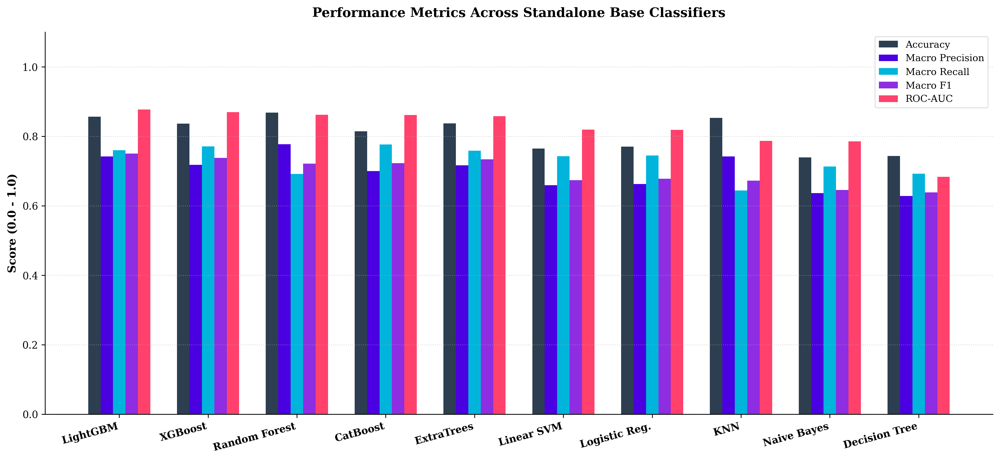

🏁 Base-classifier comparison saved: 'marburg_base_classifiers_metrics_bars.png'


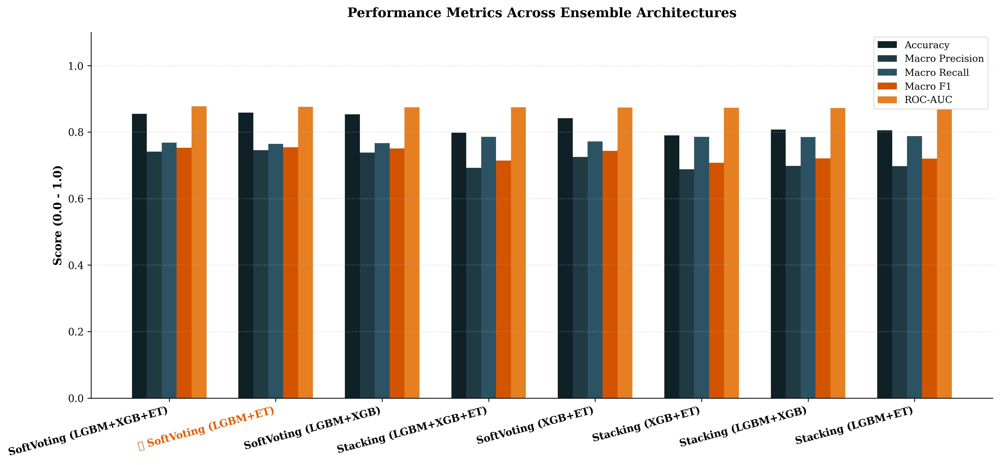

🏁 Ensemble comparison saved: 'marburg_ensemble_architectures_metrics_bars.png'


In [18]:
# =====================================================================
# PART 17: SUMMARY COMPARISON -- MULTI-METRIC GROUPED BARS
# =====================================================================
plt.rcParams['font.family'] = 'serif'

model_rename_map = {
    'LogisticRegression': 'Logistic Reg.', 'LinearSVM_SGD': 'Linear SVM',
    'DecisionTree': 'Decision Tree', 'NaiveBayes': 'Naive Bayes', 'RandomForest': 'Random Forest'
}
df_plot = final_analytics_df.copy()
df_plot['Model'] = df_plot['Model'].replace(model_rename_map)
ensemble_names = df_plot[df_plot['Model'].str.contains('Voting|Stacking')]['Model'].unique().tolist()
df_ens_plot = df_plot[df_plot['Model'].isin(ensemble_names)].sort_values(by='ROC_AUC_Macro', ascending=False).reset_index(drop=True)
df_base_plot = df_plot[~df_plot['Model'].isin(ensemble_names)].sort_values(by='ROC_AUC_Macro', ascending=False).reset_index(drop=True)

metrics_to_plot = ['Accuracy', 'Macro_Precision', 'Macro_Recall', 'Macro_F1', 'ROC_AUC_Macro']
metric_labels = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'ROC-AUC']

# Distinct color palettes: original for base models, new palette for ensembles
base_metric_colors = ['#2c3e50', '#4a00e0', '#00b4db', '#8e2de2', '#ff416c']
ensemble_metric_colors = ['#0f2027', '#203a43', '#2c5364', '#d35400', '#e67e22']

bar_width, n_metrics = 0.14, len(metrics_to_plot)

# Two full-size standalone figures rather than one figure split into two
# half-width subplots -- with 8-10 rotated model-name labels per chart,
# cramming them into half-width panels makes the labels overlap and the
# bars harder to read. Full width matters more here than fewer files.
def draw_full_chart(df_sub, title, savepath, palette=base_metric_colors, highlight=None):
    fig, ax = plt.subplots(figsize=(14, 6.5), dpi=300)
    x = np.arange(len(df_sub))
    for idx, metric in enumerate(metrics_to_plot):
        offsets = x + (idx - n_metrics / 2 + 0.5) * bar_width
        ax.bar(offsets, df_sub[metric].values, width=bar_width, color=palette[idx], label=metric_labels[idx], edgecolor='none')
    labels = [f"★ {m}" if m == highlight else m for m in df_sub['Model'].values]
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=10, rotation=15, ha='right', fontweight='bold')
    for tick in ax.get_xticklabels():
        if "★" in tick.get_text():
            tick.set_color('#e65c00')
    ax.set_ylabel("Score (0.0 - 1.0)", fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=13, pad=15, fontweight='bold')
    ax.set_ylim([0, 1.1])
    ax.grid(axis='y', linestyle=':', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.legend(loc='upper right', fontsize=9.5, framealpha=0.98, edgecolor='#e0e0e0')
    plt.tight_layout()
    plt.savefig(savepath, bbox_inches='tight', dpi=300)
    plt.show()

draw_full_chart(df_base_plot, "Performance Metrics Across Standalone Base Classifiers",
                 'marburg_base_classifiers_metrics_bars.png', palette=base_metric_colors)
print("🏁 Base-classifier comparison saved: 'marburg_base_classifiers_metrics_bars.png'")

draw_full_chart(df_ens_plot, "Performance Metrics Across Ensemble Architectures",
                 'marburg_ensemble_architectures_metrics_bars.png', palette=ensemble_metric_colors, highlight=winning_model_name)
print("🏁 Ensemble comparison saved: 'marburg_ensemble_architectures_metrics_bars.png'")

## Part 18 — External validation (independent PubChem assay)

**This is the single most important addition for credibility against MARVpred's precedent** — internal test-set performance only tells you the model works on a held-out slice of the *same* assay. MARVpred validated on a second, independent PubChem bioassay (AID 720532); this does the same, using the exact frozen champion model and the exact same feature-selection columns and scaler fitted back in Parts 2–4 (no refitting anything on this new data — that would defeat the point). Runs independently of the rest of the paper's core results; if this dataset isn't available, everything else in the notebook still stands on its own.

**Requires uploading the AID 720532 datatables to Kaggle first** (same format as AID 540276 in Part 1 — download the active/inactive datatables from the PubChem bioassay page, https://pubchem.ncbi.nlm.nih.gov/bioassay/720532). Adjust `active_path`/`inactive_path` below to wherever you upload them. If the dataset isn't found, this cell raises a clear error rather than silently skipping — it should be obvious when this section didn't run, not discovered later.

📂 Loading external validation assay (AID 720532)...
🧬 Canonicalizing external SMILES...
🧹 Removing 49 conflicting structural overlaps...
🧹 Training-assay purge: 12,940 -> 10,428
   ↳ Active: 855 | Inactive: 9,573

🧬 Extracting features...
   ✅ Featurized: 10,428 / 10,428
✅ External matrix: 10,428 × 1,943

🔮 Scoring all models on external assay...
   ↳ XGBoost                        Acc=0.673  PR-AUC=0.335
   ↳ LightGBM                       Acc=0.712  PR-AUC=0.319
   ↳ CatBoost                       Acc=0.615  PR-AUC=0.324
   ↳ RandomForest                   Acc=0.827  PR-AUC=0.416
   ↳ ExtraTrees                     Acc=0.703  PR-AUC=0.417
   ↳ DecisionTree                   Acc=0.662  PR-AUC=0.132
   ↳ NaiveBayes                     Acc=0.608  PR-AUC=0.254
   ↳ KNN                            Acc=0.880  PR-AUC=0.237
   ↳ LogisticRegression             Acc=0.612  PR-AUC=0.185
   ↳ LinearSVM_SGD                  Acc=0.613  PR-AUC=0.208
   ↳ SoftVoting (LGBM+XGB+ET)       Acc=0.702  PR-A

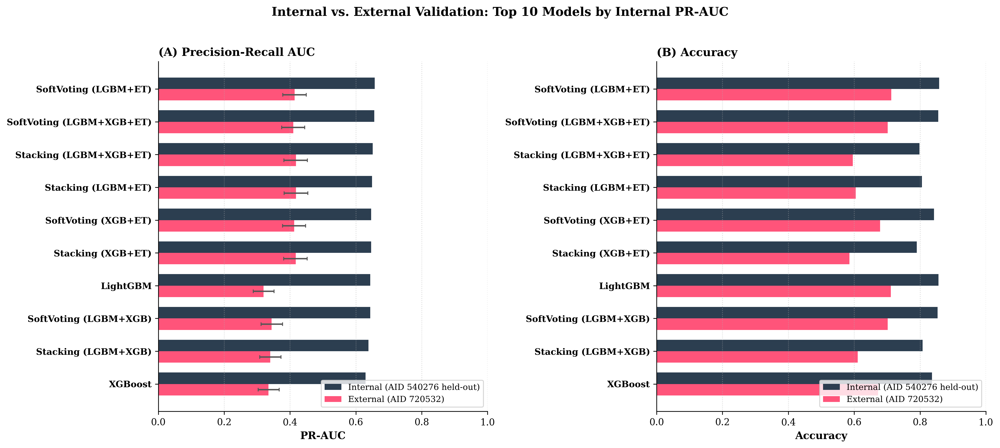

🎨 Saved: 'marburg_external_validation_all_models.png'

🏆 CHAMPION EXTERNAL RESULT: SoftVoting (LGBM+ET)
   Accuracy      : 0.7124
   PR-AUC        : 0.4140 [0.3782, 0.4495]
   ROC-AUC       : 0.8184
   Macro-F1      : 0.5606
   MCC           : 0.2732


In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import joblib
import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# PART 18: EXTERNAL VALIDATION -- ALL MODELS ON INDEPENDENT ASSAY
# =====================================================================
# Evaluates every model saved from Parts 5 & 6 on AID 720532.
# Preprocessing mirrors Parts 1-4 exactly (no ENN, no undersampling).
# =====================================================================

ext_active_path = '/kaggle/input/datasets/suyaibalsifat/aid-final/AID_720532_datatable_active.csv'
ext_inactive_path = '/kaggle/input/datasets/suyaibalsifat/aid-final/AID_720532_datatable_inactive.csv'

if not (os.path.exists(ext_active_path) and os.path.exists(ext_inactive_path)):
    raise FileNotFoundError(
        "External validation dataset (AID 720532) not found. "
        "Download from https://pubchem.ncbi.nlm.nih.gov/bioassay/720532"
    )

# ---------------------------------------------------------------------
# STEP 1: Load, canonicalize, deduplicate (mirrors Part 1)
# ---------------------------------------------------------------------
print("📂 Loading external validation assay (AID 720532)...")
df_ext_act = pd.read_csv(ext_active_path, low_memory=False).dropna(subset=[smiles_col])
df_ext_inact = pd.read_csv(ext_inactive_path, low_memory=False).dropna(subset=[smiles_col])

print("🧬 Canonicalizing external SMILES...")
df_ext_act['CANONICAL_SMILES'] = df_ext_act[smiles_col].apply(canonicalize_smiles)
df_ext_inact['CANONICAL_SMILES'] = df_ext_inact[smiles_col].apply(canonicalize_smiles)
df_ext_act = df_ext_act.dropna(subset=['CANONICAL_SMILES'])
df_ext_inact = df_ext_inact.dropna(subset=['CANONICAL_SMILES'])

# Remove intra-assay overlaps
ext_overlap = set(df_ext_act['CANONICAL_SMILES']).intersection(set(df_ext_inact['CANONICAL_SMILES']))
print(f"🧹 Removing {len(ext_overlap):,} conflicting structural overlaps...")
df_ext_act = df_ext_act[~df_ext_act['CANONICAL_SMILES'].isin(ext_overlap)].drop_duplicates(subset=['CANONICAL_SMILES'])
df_ext_inact = df_ext_inact[~df_ext_inact['CANONICAL_SMILES'].isin(ext_overlap)].drop_duplicates(subset=['CANONICAL_SMILES'])

df_ext_act['ACTIVITY'] = 1
df_ext_inact['ACTIVITY'] = 0
df_ext_all = pd.concat([
    df_ext_act[['CANONICAL_SMILES', 'ACTIVITY']],
    df_ext_inact[['CANONICAL_SMILES', 'ACTIVITY']]
], axis=0).reset_index(drop=True)

# Purge training-assay overlap
already_seen = set(df_all['CANONICAL_SMILES'])
n_before = len(df_ext_all)
df_ext_all = df_ext_all[~df_ext_all['CANONICAL_SMILES'].isin(already_seen)].reset_index(drop=True)
print(f"🧹 Training-assay purge: {n_before:,} -> {len(df_ext_all):,}")
print(f"   ↳ Active: {int((df_ext_all['ACTIVITY']==1).sum()):,} | Inactive: {int((df_ext_all['ACTIVITY']==0).sum()):,}")

# ---------------------------------------------------------------------
# STEP 2: Feature generation (mirrors Part 2)
# ---------------------------------------------------------------------
print("\n🧬 Extracting features...")
ext_features, ext_y, ext_smiles = [], [], []
failed_smiles = []
for _, row in df_ext_all.iterrows():
    feats = get_features(row['CANONICAL_SMILES'])
    if feats is not None:
        ext_features.append(feats)
        ext_y.append(row['ACTIVITY'])
        ext_smiles.append(row['CANONICAL_SMILES'])
    else:
        failed_smiles.append(row['CANONICAL_SMILES'])

if failed_smiles:
    print(f"   ⚠️ RDKit parse failures: {len(failed_smiles):,}")
print(f"   ✅ Featurized: {len(ext_features):,} / {len(df_ext_all):,}")

X_ext_raw = pd.DataFrame(np.array(ext_features), columns=all_feature_names)
y_ext = np.array(ext_y)

# Impute using training medians
X_ext_raw = X_ext_raw.replace([np.inf, -np.inf], np.nan)
X_ext_raw = X_ext_raw.fillna(X_df.median())

# ---------------------------------------------------------------------
# STEP 3: Frozen feature selection & scaling (mirrors Parts 3-4)
# ---------------------------------------------------------------------
X_ext_selected = X_ext_raw[final_feature_names].copy()
X_ext_scaled = scaler.transform(X_ext_selected)
X_ext_df = pd.DataFrame(X_ext_scaled, columns=final_feature_names)
X_ext_df = X_ext_df.replace([np.inf, -np.inf], np.nan).fillna(0)
X_ext_df = pd.DataFrame(np.clip(X_ext_df.values, -1e6, 1e6), columns=final_feature_names)

print(f"✅ External matrix: {X_ext_df.shape[0]:,} × {X_ext_df.shape[1]:,}")

# ---------------------------------------------------------------------
# STEP 4: Evaluate all saved models
# ---------------------------------------------------------------------
# Map of display names -> .pkl filenames
model_registry = {
    # Base models (Part 5)
    "XGBoost": "XGBoost_pure_enn.pkl",
    "LightGBM": "LightGBM_pure_enn.pkl",
    "CatBoost": "CatBoost_pure_enn.pkl",
    "RandomForest": "RandomForest_pure_enn.pkl",
    "ExtraTrees": "ExtraTrees_pure_enn.pkl",
    "DecisionTree": "DecisionTree_pure_enn.pkl",
    "NaiveBayes": "NaiveBayes_pure_enn.pkl",
    "KNN": "KNN_pure_enn.pkl",
    "LogisticRegression": "LogisticRegression_pure_enn.pkl",
    "LinearSVM_SGD": "LinearSVM_SGD_pure_enn.pkl",
    # Ensembles (Part 6)
    "SoftVoting (LGBM+XGB+ET)": "SoftVoting_LGBM_XGB_ET_pure_enn.pkl",
    "SoftVoting (LGBM+ET)": "SoftVoting_LGBM_ET_pure_enn.pkl",
    "SoftVoting (XGB+ET)": "SoftVoting_XGB_ET_pure_enn.pkl",
    "SoftVoting (LGBM+XGB)": "SoftVoting_LGBM_XGB_pure_enn.pkl",
    "Stacking (LGBM+ET)": "Stacking_LGBM_ET_pure_enn.pkl",
    "Stacking (XGB+ET)": "Stacking_XGB_ET_pure_enn.pkl",
    "Stacking (LGBM+XGB)": "Stacking_LGBM_XGB_pure_enn.pkl",
    "Stacking (LGBM+XGB+ET)": "Stacking_LGBM_XGB_ET_pure_enn.pkl",
}

ext_results = []
print("\n🔮 Scoring all models on external assay...")

for name, filename in model_registry.items():
    if not os.path.exists(filename):
        print(f"   ⚠️ Skipping {name} (file not found: {filename})")
        continue
    
    model = joblib.load(filename)
    y_pred = model.predict(X_ext_df)
    y_prob = model.predict_proba(X_ext_df)[:, 1]
    
    metrics = capture_metrics(f"{name}_EXT", y_ext, y_pred, y_prob, "external")
    metrics.update(bootstrap_ci(y_ext, y_prob, y_pred))
    metrics['Model'] = name  # clean name
    ext_results.append(metrics)
    
    print(f"   ↳ {name:<30} Acc={metrics['Accuracy']:.3f}  PR-AUC={metrics['PR_AUC']:.3f}")

# ---------------------------------------------------------------------
# STEP 5: Merge with internal metrics & save
# ---------------------------------------------------------------------
ext_df = pd.DataFrame(ext_results)

# Pull internal metrics from Part 6 final_analytics_df
internal_df = final_analytics_df[['Model', 'Accuracy', 'PR_AUC', 'PR_AUC_CI_Lo', 'PR_AUC_CI_Hi', 
                                   'ROC_AUC_Macro', 'Macro_F1', 'MCC']].copy()
internal_df = internal_df.rename(columns={
    'Accuracy': 'Int_Accuracy', 'PR_AUC': 'Int_PR_AUC', 
    'PR_AUC_CI_Lo': 'Int_PR_AUC_CI_Lo', 'PR_AUC_CI_Hi': 'Int_PR_AUC_CI_Hi',
    'ROC_AUC_Macro': 'Int_ROC_AUC', 'Macro_F1': 'Int_Macro_F1', 'MCC': 'Int_MCC'
})

# Merge
compare_all = ext_df[['Model', 'Accuracy', 'PR_AUC', 'PR_AUC_CI_Lo', 'PR_AUC_CI_Hi',
                      'ROC_AUC_Macro', 'Macro_F1', 'MCC']].merge(
    internal_df, on='Model', how='outer'
)

# Reorder columns for readability
col_order = ['Model', 
             'Int_Accuracy', 'Accuracy', 
             'Int_PR_AUC', 'PR_AUC', 'PR_AUC_CI_Lo', 'PR_AUC_CI_Hi',
             'Int_ROC_AUC', 'ROC_AUC_Macro',
             'Int_Macro_F1', 'Macro_F1',
             'Int_MCC', 'MCC']
compare_all = compare_all[[c for c in col_order if c in compare_all.columns]]
compare_all = compare_all.sort_values(by='Int_PR_AUC', ascending=False).reset_index(drop=True)

compare_all.to_csv('MARBURG_EXTERNAL_ALL_MODELS.csv', index=False)
print(f"\n💾 Saved: 'MARBURG_EXTERNAL_ALL_MODELS.csv' ({len(compare_all)} models)")

# ---------------------------------------------------------------------
# STEP 6: Plot -- Internal vs External PR-AUC & Accuracy
# ---------------------------------------------------------------------
plt.rcParams['font.family'] = 'serif'

# Focus on top 10 by internal PR-AUC for readability
plot_df = compare_all.head(10).copy()
plot_df = plot_df.sort_values(by='Int_PR_AUC', ascending=True).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), dpi=300)

# (A) PR-AUC comparison
ax = axes[0]
y_pos = np.arange(len(plot_df))
bar_h = 0.35
ax.barh(y_pos + bar_h/2, plot_df['Int_PR_AUC'], height=bar_h, color='#2c3e50', 
        label='Internal (AID 540276 held-out)', edgecolor='none')
ax.barh(y_pos - bar_h/2, plot_df['PR_AUC'], height=bar_h, color='#ff416c', 
        label='External (AID 720532)', edgecolor='none', xerr=[
            plot_df['PR_AUC'] - plot_df['PR_AUC_CI_Lo'],
            plot_df['PR_AUC_CI_Hi'] - plot_df['PR_AUC']
        ], ecolor='#555555', capsize=2, alpha=0.9)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Model'], fontsize=9.5, fontweight='bold')
ax.set_xlabel('PR-AUC', fontsize=11, fontweight='bold')
ax.set_title('(A) Precision-Recall AUC', fontsize=12, fontweight='bold', loc='left')
ax.set_xlim([0, 1.0])
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', fontsize=9)

# (B) Accuracy comparison
ax = axes[1]
ax.barh(y_pos + bar_h/2, plot_df['Int_Accuracy'], height=bar_h, color='#2c3e50', 
        label='Internal (AID 540276 held-out)', edgecolor='none')
ax.barh(y_pos - bar_h/2, plot_df['Accuracy'], height=bar_h, color='#ff416c', 
        label='External (AID 720532)', edgecolor='none', alpha=0.9)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Model'], fontsize=9.5, fontweight='bold')
ax.set_xlabel('Accuracy', fontsize=11, fontweight='bold')
ax.set_title('(B) Accuracy', fontsize=12, fontweight='bold', loc='left')
ax.set_xlim([0, 1.0])
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', fontsize=9)

plt.suptitle('Internal vs. External Validation: Top 10 Models by Internal PR-AUC', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('marburg_external_validation_all_models.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Saved: 'marburg_external_validation_all_models.png'")

# ---------------------------------------------------------------------
# STEP 7: Print champion external result prominently
# ---------------------------------------------------------------------
champ_ext = ext_df[ext_df['Model'] == winning_model_name]
if len(champ_ext) > 0:
    r = champ_ext.iloc[0]
    print("\n" + "="*70)
    print(f"🏆 CHAMPION EXTERNAL RESULT: {winning_model_name}")
    print(f"   Accuracy      : {r['Accuracy']:.4f}")
    print(f"   PR-AUC        : {r['PR_AUC']:.4f} [{r['PR_AUC_CI_Lo']:.4f}, {r['PR_AUC_CI_Hi']:.4f}]")
    print(f"   ROC-AUC       : {r['ROC_AUC_Macro']:.4f}")
    print(f"   Macro-F1      : {r['Macro_F1']:.4f}")
    print(f"   MCC           : {r['MCC']:.4f}")
    print("="*70)

## Part 19 — Applicability domain (Tanimoto-based)

A model's predictions are only trustworthy for compounds structurally similar to what it was trained on — this defines that boundary explicitly rather than leaving it implicit. For each test compound, this finds its nearest neighbor (by Tanimoto similarity on raw Morgan fingerprints, not the scaled/selected feature set) among the training compounds, and sets the applicability domain threshold from the training set's own internal nearest-neighbor similarity distribution (5th percentile) — a data-driven cutoff, not an arbitrary fixed number. Reports what fraction of the test set falls inside/outside, and whether model accuracy actually holds up within the defined domain (it should, by construction — if it doesn't, that's worth knowing before submission, not after review).

🧬 Computing raw Morgan fingerprints for applicability domain analysis...
   ↳ Subsampled training reference to 3,000 compounds (from 22,036) for tractable pairwise comparison.
   ↳ 3,000 training reference fingerprints, 5,510 test fingerprints.
📏 Establishing the applicability domain threshold from the training set's own internal nearest-neighbor distances...
   ↳ AD threshold (5th percentile of training internal NN similarity): 0.2800
📏 Computing nearest-neighbor similarity for every test compound against the training reference...

📊 94.2% of the test set falls within the applicability domain (Tc >= 0.2800).


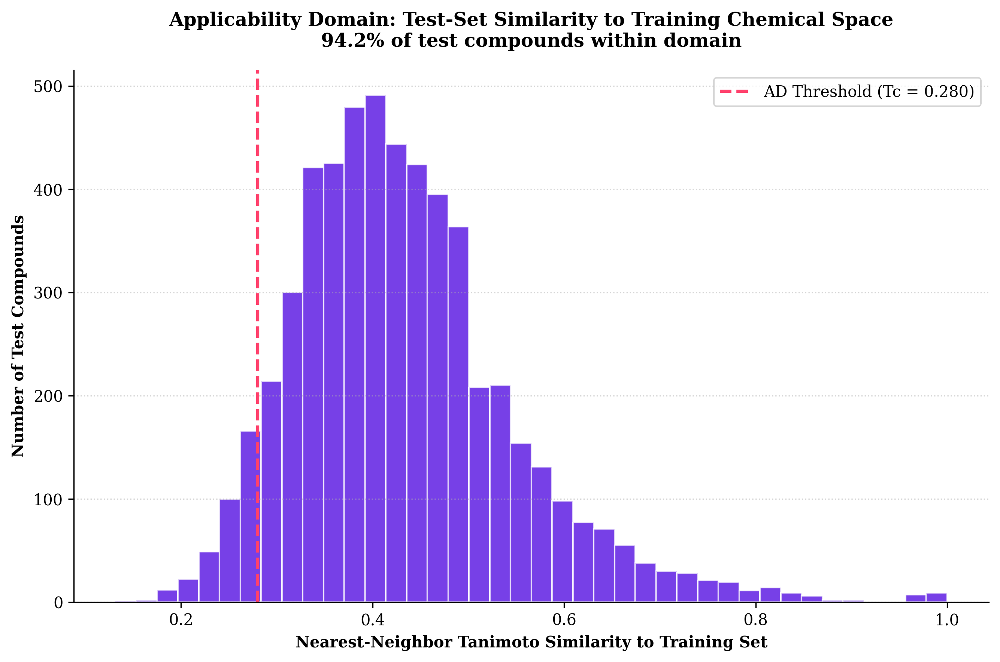

🎨 Saved: 'marburg_applicability_domain.png'

📊 Champion Accuracy inside AD: 0.8606 (n=5193)  |  outside AD: 0.8202 (n=317)
💾 Saved: 'MARBURG_APPLICABILITY_DOMAIN.csv'


In [19]:
from rdkit import DataStructs

# =====================================================================
# PART 19: APPLICABILITY DOMAIN -- TANIMOTO NEAREST-NEIGHBOR SIMILARITY
# =====================================================================
print("🧬 Computing raw Morgan fingerprints for applicability domain analysis...")

def get_fp(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    return morgan_gen.GetFingerprint(mol) if mol is not None else None

# Reference set = training compounds actually used to fit the model
# (pre-ENN pool -- ENN only removes noisy majority-class rows near the
# decision boundary, so the pre-ENN pool is the more honest representation
# of the chemical space the model was originally exposed to).
train_ref_smiles = smiles_train_raw
if len(train_ref_smiles) > 3000:
    rng_ad = np.random.RandomState(42)
    train_ref_smiles = rng_ad.choice(train_ref_smiles, size=3000, replace=False)
    print(f"   ↳ Subsampled training reference to 3,000 compounds (from {len(smiles_train_raw):,}) for tractable pairwise comparison.")

train_fps = [fp for fp in (get_fp(s) for s in train_ref_smiles) if fp is not None]
test_fps = [fp for fp in (get_fp(s) for s in smiles_test) if fp is not None]
print(f"   ↳ {len(train_fps):,} training reference fingerprints, {len(test_fps):,} test fingerprints.")

print("📏 Establishing the applicability domain threshold from the training set's own internal nearest-neighbor distances...")
train_nn_sims = []
for i, fp in enumerate(train_fps):
    others = train_fps[:i] + train_fps[i+1:]
    sims = DataStructs.BulkTanimotoSimilarity(fp, others)
    train_nn_sims.append(max(sims) if sims else 0.0)
ad_threshold = np.percentile(train_nn_sims, 5)
print(f"   ↳ AD threshold (5th percentile of training internal NN similarity): {ad_threshold:.4f}")

print("📏 Computing nearest-neighbor similarity for every test compound against the training reference...")
test_nn_sims = np.array([max(DataStructs.BulkTanimotoSimilarity(fp, train_fps)) for fp in test_fps])

in_domain = test_nn_sims >= ad_threshold
pct_in_domain = 100 * np.mean(in_domain)
print(f"\n📊 {pct_in_domain:.1f}% of the test set falls within the applicability domain (Tc >= {ad_threshold:.4f}).")

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)
ax.hist(test_nn_sims, bins=40, color='#4a00e0', alpha=0.75, edgecolor='white')
ax.axvline(x=ad_threshold, color='#ff416c', linestyle='--', linewidth=2, label=f'AD Threshold (Tc = {ad_threshold:.3f})')
ax.set_xlabel("Nearest-Neighbor Tanimoto Similarity to Training Set", fontsize=10, fontweight='bold')
ax.set_ylabel("Number of Test Compounds", fontsize=10, fontweight='bold')
ax.set_title(f"Applicability Domain: Test-Set Similarity to Training Chemical Space\n{pct_in_domain:.1f}% of test compounds within domain",
             fontsize=12, pad=15, fontweight='bold')
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('marburg_applicability_domain.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Saved: 'marburg_applicability_domain.png'")

# Does accuracy actually hold up inside vs. outside the domain?
y_test_arr_ad = np.asarray(y_test)[:len(test_fps)]
y_pred_champion_ad = champion_model.predict(X_test_df)[:len(test_fps)]
acc_in = accuracy_score(y_test_arr_ad[in_domain], y_pred_champion_ad[in_domain]) if in_domain.sum() > 0 else float('nan')
acc_out = accuracy_score(y_test_arr_ad[~in_domain], y_pred_champion_ad[~in_domain]) if (~in_domain).sum() > 0 else float('nan')
print(f"\n📊 Champion Accuracy inside AD: {acc_in:.4f} (n={int(in_domain.sum())})  |  outside AD: {acc_out:.4f} (n={int((~in_domain).sum())})")

pd.DataFrame({'SMILES': smiles_test[:len(test_fps)], 'NN_Tanimoto': test_nn_sims, 'In_Domain': in_domain}).to_csv('MARBURG_APPLICABILITY_DOMAIN.csv', index=False)
print("💾 Saved: 'MARBURG_APPLICABILITY_DOMAIN.csv'")

## Part 20 — Molecular docking (exploratory, GP1 structural surrogate)

**Read this before running.** No experimentally resolved structure exists for the actual Gene 4 Small ORF target, so — matching MARVpred's own approach — this docks against Marburg GP1 (PDB **5UQY**) as a structural surrogate, using AutoDock Vina via the `vina` + `meeko` Python bindings (no MGLTools/PyRx installation needed). Two things require your judgment before the results mean anything:

1. **5UQY is an antibody-antigen complex** (GP1 bound to the human antibody MR78), not a small-molecule complex — there's no co-crystallized ligand to define a precise binding pocket from. This runs **blind docking** (search box spanning the whole GP1 chain) as the conservative default. Visually inspect the top poses in PyMOL/Chimera before reporting specific residue-level interactions.
2. **Chain identification is automatic but unverified** — the code below picks the largest protein chain by residue count as GP1 (the antibody heavy/light chains are typically shorter), and prints all chain sizes so you can confirm this picked correctly.

Docks only the top ~30 highest-confidence predicted actives (not the whole test set) — each ligand takes seconds, so this is a 10-20 minute cell, not a bottleneck. Treat this as **supporting, exploratory evidence** for the Discussion section, the same role it plays in MARVpred — not a primary result.

In [20]:
!pip install gemmi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 35.8 MB/s eta 0:00:0000:0100:01


📦 Installing system and Python docking dependencies...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.0/294.0 kB 7.6 MB/s eta 0:00:00
📥 Downloading PDB 5UQY (Marburg GP1 + antibody MR78)...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


🎯 Target selected: Chain 'A' (Marburg GP1 core subunit)
⚙️ Converting gp1_receptor.pdb to gp1_receptor.pdbqt using OpenBabel...

📐 Blind docking box: center=[115.8, 44.5, 113.8] Å, size=[30.0, 30.0, 30.0] Å

🧪 Preparing top 30 predicted-active compounds for docking...
Computing Vina grid ... done.
Performing docking (random seed: -1116468261) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
   ↳ [1/30] Score: -6.39 kcal/mol

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.393          0          0
   2       -6.139      3.765       7.42
   3       -5.847      3.253      6.501
   4       -5.789      2.241      4.223
   5       -5.767      4.007      6.396
Performing docking (random seed: -1116468261) ...    ↳ [2/30] Score: -6.82 kcal/mol

0%   10   20   30   40   50   60   70   80   90  

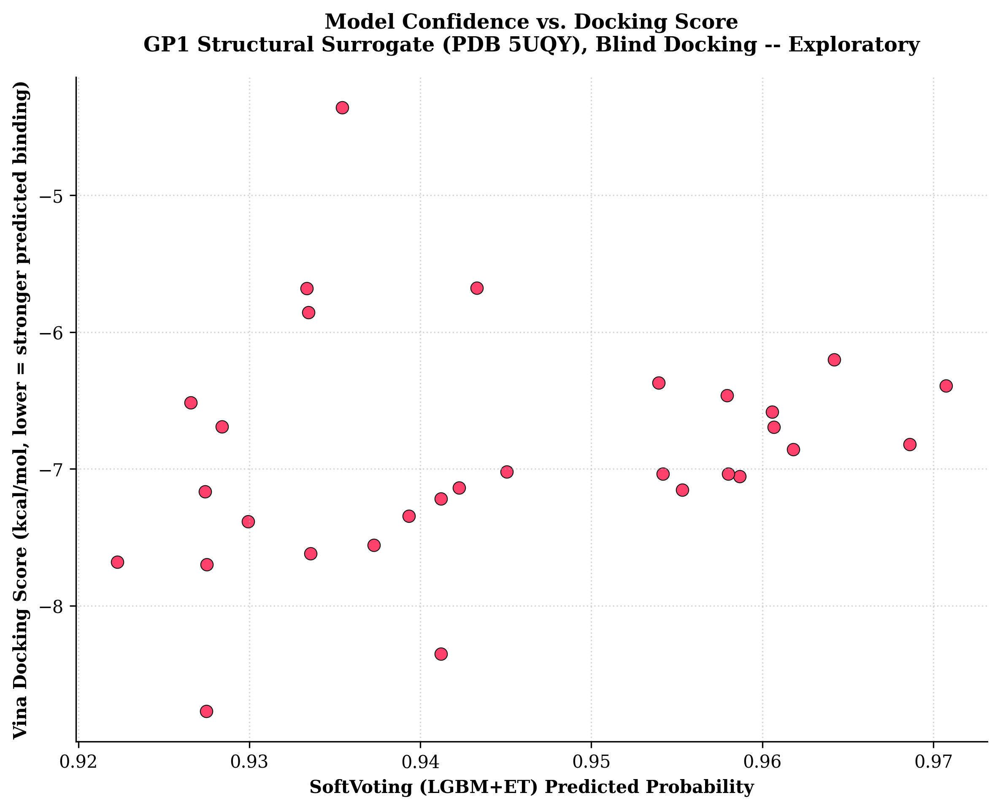

🎨 Saved: 'marburg_docking_vs_confidence.png'


In [21]:
import os
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# =====================================================================
# PART 20: MOLECULAR DOCKING -- GP1 STRUCTURAL SURROGATE (PDB 5UQY)
# =====================================================================
print("📦 Installing system and Python docking dependencies...")
os.system("apt-get update -qq && apt-get install -y -qq openbabel > /dev/null")
os.system("pip install -q vina meeko requests rdkit")

import requests
from rdkit import Chem
from rdkit.Chem import AllChem, rdmolops
from meeko import MoleculePreparation, PDBQTWriterLegacy
from vina import Vina

def get_largest_fragment(mol):
    """Extracts the largest fragment to strip salts/counterions/solvents."""
    if mol is None:
        return None
    frags = rdmolops.GetMolFrags(mol, asMols=True)
    if len(frags) == 1:
        return mol
    # Pick the fragment with the highest heavy atom count
    return max(frags, key=lambda f: f.GetNumHeavyAtoms())

# --- 1. Fetch receptor structure ---
pdb_path = '5uqy.pdb'
if not os.path.exists(pdb_path):
    print("📥 Downloading PDB 5UQY (Marburg GP1 + antibody MR78)...")
    r = requests.get('https://files.rcsb.org/download/5UQY.pdb')
    r.raise_for_status()
    with open(pdb_path, 'w') as f:
        f.write(r.text)

# Chain A is the Marburg GP1 core monomer
gp1_chain = 'A'
print(f"🎯 Target selected: Chain '{gp1_chain}' (Marburg GP1 core subunit)")

# --- 2. Isolate GP1 chain and convert to PDBQT ---
gp1_only_path = 'gp1_receptor.pdb'
with open(pdb_path) as f_in, open(gp1_only_path, 'w') as f_out:
    for line in f_in:
        if line.startswith('ATOM') and line[21] == gp1_chain:
            f_out.write(line)
    f_out.write('END\n')

receptor_pdbqt = 'gp1_receptor.pdbqt'
print(f"⚙️ Converting {gp1_only_path} to {receptor_pdbqt} using OpenBabel...")
obabel_cmd = f"obabel {gp1_only_path} -O {receptor_pdbqt} -xr"
res = subprocess.run(obabel_cmd, shell=True, capture_output=True, text=True)

if not os.path.exists(receptor_pdbqt):
    raise RuntimeError(f"OpenBabel failed to generate {receptor_pdbqt}:\n{res.stderr}")

# Calculate box, capping max dimension at 30 Å to avoid Vina grid overflow warnings
coords = []
with open(gp1_only_path) as f:
    for line in f:
        if line.startswith('ATOM'):
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
coords = np.array(coords)
box_center = coords.mean(axis=0)
raw_size = (coords.max(axis=0) - coords.min(axis=0)) + 5.0
box_size = np.clip(raw_size, 15.0, 30.0)  # Keep box within 30 Å bounds

print(f"\n📐 Blind docking box: center={box_center.round(1).tolist()} Å, size={box_size.round(1).tolist()} Å")

# --- 3. Prepare top-confidence predicted-active ligands and dock ---
top_leads = df_ranked[df_ranked['True_Label'].notna()].sort_values(by='Prob', ascending=False).head(30)
print(f"\n🧪 Preparing top {len(top_leads)} predicted-active compounds for docking...")

vina_results = []
v = Vina(sf_name='vina')
v.set_receptor(receptor_pdbqt)
v.compute_vina_maps(center=box_center.tolist(), box_size=box_size.tolist())

for i, (_, row) in enumerate(top_leads.iterrows(), 1):
    smiles = row['SMILES']
    try:
        raw_mol = Chem.MolFromSmiles(smiles)
        mol = get_largest_fragment(raw_mol)
        
        if mol is None:
            raise ValueError("Failed to parse valid RDKit molecule")
            
        mol = Chem.AddHs(mol)
        
        # 3D Conformer generation
        if AllChem.EmbedMolecule(mol, randomSeed=42) != 0:
            AllChem.EmbedMolecule(mol, useRandomCoords=True, randomSeed=42)
        AllChem.MMFFOptimizeMolecule(mol)
        
        # Meeko preparation
        preparator = MoleculePreparation()
        mol_setups = preparator.prepare(mol)
        pdbqt_string = PDBQTWriterLegacy.write_string(mol_setups[0])[0]
        
        ligand_path = f'ligand_{i}.pdbqt'
        with open(ligand_path, 'w') as f:
            f.write(pdbqt_string)

        v.set_ligand_from_file(ligand_path)
        v.dock(exhaustiveness=8, n_poses=5)
        score = v.energies(n_poses=1)[0][0]
        vina_results.append({'SMILES': smiles, 'Predicted_Prob': row['Prob'], 'Vina_Score_kcal_mol': score})
        print(f"   ↳ [{i}/{len(top_leads)}] Score: {score:.2f} kcal/mol")
    except Exception as e:
        print(f"   ↳ [{i}/{len(top_leads)}] Failed to dock: {e}")

df_docking = pd.DataFrame(vina_results).sort_values(by='Vina_Score_kcal_mol')
df_docking.to_csv('MARBURG_DOCKING_RESULTS.csv', index=False)
print(f"\n💾 Saved: 'MARBURG_DOCKING_RESULTS.csv' ({len(df_docking)} compounds docked)")

if len(df_docking) > 1:
    corr = df_docking['Predicted_Prob'].corr(df_docking['Vina_Score_kcal_mol'])
    print(f"📊 Correlation between model confidence and docking score: r = {corr:.3f}")

# Plot results
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(8, 6.5), dpi=300)
ax.scatter(df_docking['Predicted_Prob'], df_docking['Vina_Score_kcal_mol'], color='#ff416c', s=50, edgecolor='#111111', linewidth=0.5)
ax.set_xlabel(f"{winning_model_name} Predicted Probability", fontsize=10, fontweight='bold')
ax.set_ylabel("Vina Docking Score (kcal/mol, lower = stronger predicted binding)", fontsize=10, fontweight='bold')
ax.set_title("Model Confidence vs. Docking Score\nGP1 Structural Surrogate (PDB 5UQY), Blind Docking -- Exploratory",
             fontsize=11.5, pad=15, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('marburg_docking_vs_confidence.png', bbox_inches='tight', dpi=300)
plt.show()
print("🎨 Saved: 'marburg_docking_vs_confidence.png'")

## Part 21 — 5-fold cross-validation: base vs. ensemble robustness

**Added on request, as a genuine robustness layer on top of the single 80/20 split** — not a replacement for it. The single split (Parts 3–17) remains the primary analysis and the one all the interpretability/diagnostic work is built on, since SHAP, LIME, scaffold analysis, etc. all need one fixed, specific fitted model, not five different fold-specific ones. This section asks a narrower, complementary question: **does the ensemble's advantage over the best base model hold up across different data splits, or was Part 6's result a property of one particular 80/20 split?**

Each of the 5 folds independently repeats the same leakage discipline as the main pipeline (ENN and scaling fit strictly on that fold's training portion, applied — never refit — to that fold's validation portion). Hyperparameters are **fixed at the values Part 5 already tuned** — no re-running GridSearchCV per fold, which is what makes this computationally tractable (the grids in Part 5 were also trimmed for the same reason). All 18 models (10 base + 8 ensembles) are evaluated on every fold; results are saved as both the full per-fold table and a per-model mean±std summary.

🔁 Running 5-fold CV for base-vs-ensemble robustness (fixed hyperparameters from Part 5, no re-tuning per fold)...

──────────────────────────────────────────────────────────
Fold 1/5
──────────────────────────────────────────────────────────
   ↳ XGBoost: Accuracy=0.8439, PR-AUC=0.6475
   ↳ LightGBM: Accuracy=0.8672, PR-AUC=0.6719
   ↳ CatBoost: Accuracy=0.8136, PR-AUC=0.6300
   ↳ RandomForest: Accuracy=0.8746, PR-AUC=0.6481
   ↳ ExtraTrees: Accuracy=0.8425, PR-AUC=0.6404
   ↳ DecisionTree: Accuracy=0.7505, PR-AUC=0.3383
   ↳ NaiveBayes: Accuracy=0.7452, PR-AUC=0.4613
   ↳ KNN: Accuracy=0.8535, PR-AUC=0.5249
   ↳ LogisticRegression: Accuracy=0.7704, PR-AUC=0.5101
   ↳ LinearSVM_SGD: Accuracy=0.7668, PR-AUC=0.5122
   ↳ SoftVoting (LGBM+XGB+ET): Accuracy=0.8603, PR-AUC=0.6792
   ↳ SoftVoting (LGBM+ET): Accuracy=0.8657, PR-AUC=0.6825
   ↳ SoftVoting (XGB+ET): Accuracy=0.8468, PR-AUC=0.6671
   ↳ SoftVoting (LGBM+XGB): Accuracy=0.8592, PR-AUC=0.6678
   ↳ Stacking (LGBM+ET): Accuracy=0.8069,

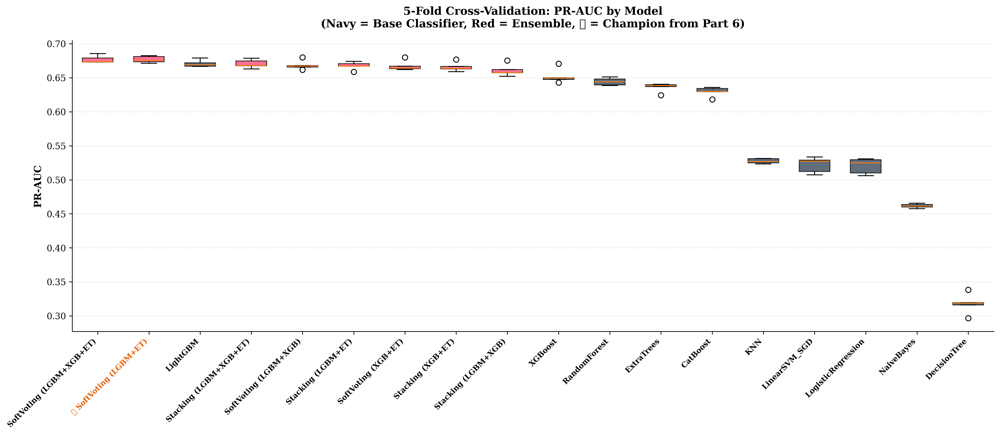

🎨 Saved: 'marburg_kfold_comparison_pr_auc.png'


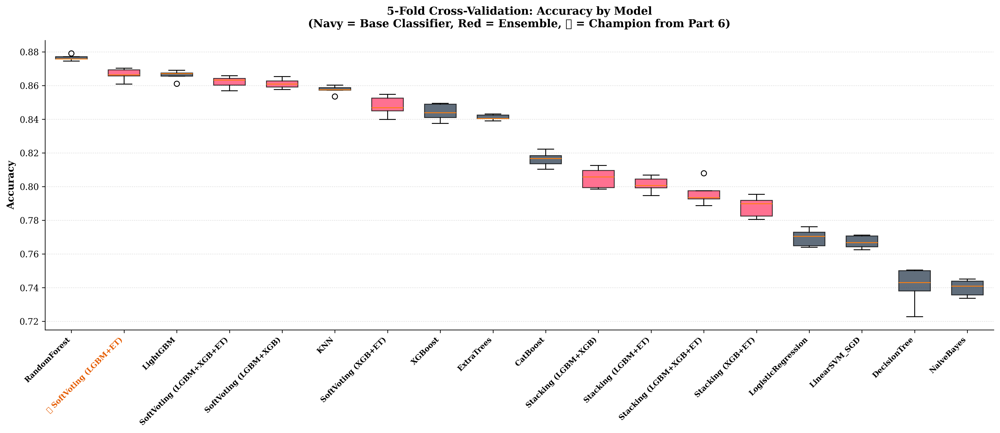

🎨 Saved: 'marburg_kfold_comparison_accuracy.png'


In [26]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold as SKFold_CV
from sklearn.preprocessing import StandardScaler as Scaler_CV
from imblearn.under_sampling import EditedNearestNeighbours as ENN_CV

# Suppress Python 3.12 datetime deprecation noise from Jupyter worker threads
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# =====================================================================
# PART 21: 5-FOLD CROSS-VALIDATION -- BASE vs. ENSEMBLE ROBUSTNESS
# =====================================================================
print("🔁 Running 5-fold CV for base-vs-ensemble robustness (fixed hyperparameters from Part 5, no re-tuning per fold)...")

# Recombine the leakage-free, feature-selected train+test pool from Part 3
X_cv_pool = pd.concat([X_train_final, X_test_final], axis=0).reset_index(drop=True)
y_cv_pool = np.concatenate([y_train_raw, y_test])

def build_model(name, params, spw):
    ctors = {
        "XGBoost": lambda: xgb.XGBClassifier(tree_method='hist', scale_pos_weight=spw, eval_metric='aucpr', random_state=42, **params),
        "LightGBM": lambda: lgb.LGBMClassifier(scale_pos_weight=spw, metric='binary_logloss', random_state=42, verbosity=-1, **params),
        "CatBoost": lambda: CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=42, **params),
        "RandomForest": lambda: RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=42, **params),
        "ExtraTrees": lambda: ExtraTreesClassifier(class_weight='balanced', n_jobs=-1, random_state=42, **params),
        "DecisionTree": lambda: DecisionTreeClassifier(class_weight='balanced', random_state=42, **params),
        "NaiveBayes": lambda: BernoulliNB(**params),
        "KNN": lambda: KNeighborsClassifier(n_jobs=-1, **params),
        "LogisticRegression": lambda: LogisticRegression(class_weight='balanced', solver='lbfgs', penalty='l2', max_iter=200, random_state=42, **params),
        "LinearSVM_SGD": lambda: SGDClassifier(loss='log_loss', class_weight='balanced', tol=1e-3, max_iter=1000, random_state=42, **params),
    }
    return ctors[name]()

outer_cv = SKFold_CV(n_splits=5, shuffle=True, random_state=42)
fold_records = []

for fold_idx, (train_idx, val_idx) in enumerate(outer_cv.split(X_cv_pool, y_cv_pool), 1):
    print(f"\n──────────────────────────────────────────────────────────")
    print(f"Fold {fold_idx}/5")
    print(f"──────────────────────────────────────────────────────────")
    X_fold_train_raw, X_fold_val_raw = X_cv_pool.iloc[train_idx], X_cv_pool.iloc[val_idx]
    y_fold_train_raw, y_fold_val = y_cv_pool[train_idx], y_cv_pool[val_idx]

    # Apply ENN per fold
    enn_fold = ENN_CV(sampling_strategy='majority', n_neighbors=3)
    X_fold_train_enn, y_fold_train = enn_fold.fit_resample(X_fold_train_raw, y_fold_train_raw)
    fold_spw = np.sum(y_fold_train == 0) / np.sum(y_fold_train == 1)

    # Scale and handle non-finite bounds safely per fold
    scaler_fold = Scaler_CV()
    X_fold_train_scaled = scaler_fold.fit_transform(X_fold_train_enn)
    X_fold_val_scaled = scaler_fold.transform(X_fold_val_raw)

    X_fold_train_df = pd.DataFrame(X_fold_train_scaled, columns=final_feature_names).replace([np.inf, -np.inf], np.nan).fillna(0)
    X_fold_val_df = pd.DataFrame(X_fold_val_scaled, columns=final_feature_names).replace([np.inf, -np.inf], np.nan).fillna(0)

    # Clip values to ensure tree model numerical stability
    X_fold_train_df = pd.DataFrame(np.clip(X_fold_train_df.values, -1e6, 1e6), columns=final_feature_names)
    X_fold_val_df = pd.DataFrame(np.clip(X_fold_val_df.values, -1e6, 1e6), columns=final_feature_names)

    fold_fitted = {}
    for name, params in best_hyperparams.items():
        m = build_model(name, params, fold_spw)
        m.fit(X_fold_train_df, y_fold_train)
        y_pred, y_prob = m.predict(X_fold_val_df), m.predict_proba(X_fold_val_df)[:, 1]
        metrics = capture_metrics(name, y_fold_val, y_pred, y_prob, str(params))
        metrics['Fold'], metrics['Model_Type'] = fold_idx, 'Base'
        fold_records.append(metrics)
        fold_fitted[name] = m
        print(f"   ↳ {name}: Accuracy={metrics['Accuracy']:.4f}, PR-AUC={metrics['PR_AUC']:.4f}")

    # Rebuild fold-specific ensembles
    lgbm_f, xgb_f, et_f = fold_fitted['LightGBM'], fold_fitted['XGBoost'], fold_fitted['ExtraTrees']
    fold_ensemble_jobs = [
        ('SoftVoting', 'SoftVoting (LGBM+XGB+ET)', [('LightGBM', lgbm_f), ('XGBoost', xgb_f), ('ExtraTrees', et_f)]),
        ('SoftVoting', 'SoftVoting (LGBM+ET)', [('LightGBM', lgbm_f), ('ExtraTrees', et_f)]),
        ('SoftVoting', 'SoftVoting (XGB+ET)', [('XGBoost', xgb_f), ('ExtraTrees', et_f)]),
        ('SoftVoting', 'SoftVoting (LGBM+XGB)', [('LightGBM', lgbm_f), ('XGBoost', xgb_f)]),
        ('Stacking', 'Stacking (LGBM+ET)', [('LightGBM', lgbm_f), ('ExtraTrees', et_f)]),
        ('Stacking', 'Stacking (XGB+ET)', [('XGBoost', xgb_f), ('ExtraTrees', et_f)]),
        ('Stacking', 'Stacking (LGBM+XGB)', [('LightGBM', lgbm_f), ('XGBoost', xgb_f)]),
        ('Stacking', 'Stacking (LGBM+XGB+ET)', [('LightGBM', lgbm_f), ('XGBoost', xgb_f), ('ExtraTrees', et_f)]),
    ]
    for etype, ename, comps in fold_ensemble_jobs:
        cloned = [(k, clone(m)) for k, m in comps]
        if etype == 'Stacking':
            ens = StackingClassifier(estimators=cloned, final_estimator=LogisticRegression(class_weight='balanced', max_iter=200, random_state=42), cv=3, n_jobs=-1)
        else:
            ens = VotingClassifier(estimators=cloned, voting='soft', n_jobs=-1)
        ens.fit(X_fold_train_df, y_fold_train)
        y_pred_e, y_prob_e = ens.predict(X_fold_val_df), ens.predict_proba(X_fold_val_df)[:, 1]
        metrics_e = capture_metrics(ename, y_fold_val, y_pred_e, y_prob_e, etype)
        metrics_e['Fold'], metrics_e['Model_Type'] = fold_idx, 'Ensemble'
        fold_records.append(metrics_e)
        print(f"   ↳ {ename}: Accuracy={metrics_e['Accuracy']:.4f}, PR-AUC={metrics_e['PR_AUC']:.4f}")

df_cv_folds = pd.DataFrame(fold_records)
df_cv_folds.to_csv('MARBURG_KFOLD_CV_RESULTS.csv', index=False)
print(f"\n💾 Saved fold-wise results: 'MARBURG_KFOLD_CV_RESULTS.csv' ({len(df_cv_folds)} rows = 18 models x 5 folds)")

cv_summary = df_cv_folds.groupby(['Model', 'Model_Type'])[['Accuracy', 'PR_AUC', 'ROC_AUC_Macro', 'Macro_F1', 'MCC']].agg(['mean', 'std']).reset_index()
cv_summary.columns = ['_'.join(c).strip('_') for c in cv_summary.columns]
cv_summary.to_csv('MARBURG_KFOLD_CV_SUMMARY.csv', index=False)
print("💾 Saved per-model fold summary: 'MARBURG_KFOLD_CV_SUMMARY.csv'")
print("\n📊 Top 10 by mean PR-AUC across folds:")
print(cv_summary.sort_values(by='PR_AUC_mean', ascending=False).head(10).to_string(index=False))

# --- Fold-wise comparison plots: base (navy) vs ensemble (red), champion starred ---
plt.rcParams['font.family'] = 'serif'

def fold_boxplot(metric_col, metric_label, savepath):
    order = df_cv_folds.groupby('Model')[metric_col].mean().sort_values(ascending=False).index.tolist()
    data_by_model = [df_cv_folds[df_cv_folds['Model'] == m][metric_col].values for m in order]
    box_colors = ['#ff416c' if df_cv_folds[df_cv_folds['Model'] == m]['Model_Type'].iloc[0] == 'Ensemble' else '#2c3e50' for m in order]

    fig, ax = plt.subplots(figsize=(16, 7), dpi=300)
    bp = ax.boxplot(data_by_model, patch_artist=True, widths=0.6)
    for patch, color in zip(bp['boxes'], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    labels = [f"★ {m}" if m == winning_model_name else m for m in order]
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8.5, fontweight='bold')
    for tick in ax.get_xticklabels():
        if "★" in tick.get_text():
            tick.set_color('#e65c00')
    ax.set_ylabel(metric_label, fontsize=11, fontweight='bold')
    ax.set_title(f"5-Fold Cross-Validation: {metric_label} by Model\n(Navy = Base Classifier, Red = Ensemble, ★ = Champion from Part 6)",
                 fontsize=12.5, fontweight='bold', pad=15)
    ax.grid(axis='y', linestyle=':', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(savepath, bbox_inches='tight', dpi=300)
    plt.show()

fold_boxplot('PR_AUC', 'PR-AUC', 'marburg_kfold_comparison_pr_auc.png')
print("🎨 Saved: 'marburg_kfold_comparison_pr_auc.png'")
fold_boxplot('Accuracy', 'Accuracy', 'marburg_kfold_comparison_accuracy.png')
print("🎨 Saved: 'marburg_kfold_comparison_accuracy.png'")